**Name:** Xinghang ZENG 曾星航

**EID:** 72656014

# Tutorial 5: Image Segmentation using Clustering

In this tutorial you will use clustering algorithms to generate a segmentation of an image.  An image segmentation is a separation of an image into regions belonging to distinct objects.
First we need to initialize Python.  Run the below cell.

**Note**: The recommended version of scikit-learn for this tutorial is **1.4.2**. There may be bugs if you use other versions.

In [1]:
%matplotlib inline
# setup output image format (Chrome works best)
# jpg is better for images
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpg")
import warnings
# sklearn 1.3 warns that the default n_init will change in 1.4 (also inside GMM's kmeans init)
warnings.filterwarnings('ignore', message='The default value of `n_init`', category=FutureWarning)

import glob
import os
import random
import matplotlib.pyplot as plt
from numpy import zeros, array, arange, floor, mean, unique, asarray, ix_, float64
from sklearn import cluster, mixture, metrics, preprocessing, model_selection
import skimage.io
import skimage.color
import skimage.util

random.seed(100)

## 1. Loading Data and Pre-processing
Next we need to load the data.  Download `imgdb.zip`, and unzip it in the same directory as this ipynb file.  Then run the following cell to load the image data.

In [2]:
filelist = glob.glob('imgdb/jpg/*.jpg')
gtpath   = 'imgdb/gtruth/'
if len(filelist) == 0:
  raise Exception("Could not find imgdb directory!  " +
               "Make sure you put it here: " + os.getcwd() )
else:
    imgdata = []
    gtdata  = []

    # load image data
    for f in filelist:
        # load image - byte [0 to 255]
        img = skimage.io.imread(f)

        (fdir1, fname)  = os.path.split(f)

        # load GT segmentation (non-consecutive integers)
        gname = gtpath + fname[:-4] + "-gt.png"
        gtimg = skimage.io.imread(gname)

        # convert to consecutive integers
        cl = unique(gtimg)
        gtimg0 = gtimg.copy().astype(float64)
        for i in range(len(cl)):
            gtimg0[gtimg==cl[i]] = i

        imgdata.append(img)
        gtdata.append(gtimg0)
print(len(imgdata))

14


There are 14 images.  Each image also has a ground-truth segmentation that was created by a human annotation.  Here is an example:

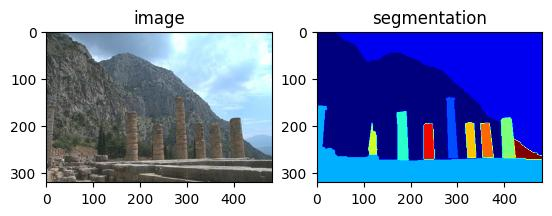

In [3]:
plt.subplot(1,2,1)
plt.imshow(imgdata[6], aspect='equal')# change the image: image[0-13]
plt.title('image')
plt.subplot(1,2,2)
plt.imshow(gtdata[6], aspect='equal', cmap='jet')
plt.title('segmentation');

## 2. Clustering with Color Features
To segment an image, we will extract features from each pixel location.  Then, we cluster the extracted features into groups.  Pixel location that are clustered into the same group form a segment.

For the features, we will use the "Lab" colorspace, rather than the RGB colors.  Also, we will ignore the "L" feature, which is brightness, resulting in a 2-dimensional color feature space (a, b). Here are a few helper functions:
- getfeatures(): Extract Lab features along a regular grid on the image;
- labels2seg(): Convert cluster labels into a segmentation image;
- colorsegms(): Color a segmentation image using colors from the original image.

In [4]:
def getfeatures(img, segm=None, stepsize=7, use_loc = False):
    """
    getfeatures - extract features from an image
     [X, Y, L] = getfeatures(img, stepsize)
     INPUT
     img      - the image   [type = np.ndarray or Image]
     segm     - the gt segmentation (optional)
     stepsize - window stepsize
     OUTPUT
      X   - the features: each row is a feature vector  [type = np.ndarray]
      Y   - the GT segment labels for each feature (if segm is provided)
      L   - dictionary containing location information of each feature
    """
    winsize = 7 # ensure it is an odd number
    if stepsize > winsize:
        raise Exception('stepsize larger than window size')
    # convert to LAB
    yimg = skimage.color.rgb2lab(img)

    offset = floor((winsize-1)/2)
    sy,sx, sc = img.shape

    if use_loc:
        Xdim = 4
    else:
        Xdim = 2

    # extract window patches with stepsize
    patches = skimage.util.view_as_windows(yimg, (winsize, winsize, 3), step=stepsize)
    psize = patches.shape

    # get coordinates of windows
    rangex = arange(psize[1])*stepsize + offset
    rangey = arange(psize[0])*stepsize + offset

    X = zeros((psize[0] * psize[1], Xdim));

    if segm is None:
        Y = None
    else:
        Y = zeros((X.shape[0],))

    i = 0
    for x in range(psize[1]):
        for y in range(psize[0]):
            myu = mean(patches[y,x,0,:,:,1].flatten())
            myv = mean(patches[y,x,0,:,:,2].flatten())
            myy = int(rangey[y])
            myx = int(rangex[x])

            if use_loc:
                X[i,:] = [myu, myv, myx, myy]
            else:
                X[i,:] = [myu, myv]

            if Y is not None:
                Y[i] = segm[myy, myx]

            i = i + 1

    L = {'rangex':rangex, 'rangey':rangey, 'offset':offset, 'sx':sx, 'sy':sy, \
         'stepsize':stepsize, 'winsize':winsize}
    return X, Y, L

def labels2seg(Y,L):
    """
    labels2segm - form a segmentation image using cluster labels
    segm = labels2segm(Y, L)
    Y - cluster labels for each location
    L - location dictionary from getfeatures
    segm - output segmentation image
    """
    segm = zeros((L['sy'], L['sx']))
    # <= offset if floor((winsize-1)/2)>= floor(stepsize/2)
    rstep = int(floor(L['stepsize']/2.0))
    stepbox = range(-rstep, L['stepsize'] - rstep)
    rx = asarray(L['rangex'], dtype=int) + int(L['offset'])
    ry = asarray(L['rangey'], dtype=int) + int(L['offset'])
    Y_reshaped = Y.reshape((ry.size, rx.size),order='F')
    for i in stepbox:
        for j in stepbox:
            segm[ix_(ry + j, rx + i)] = Y_reshaped
    ## Now fil in the borders if they are missing
    minx = min(rx) + stepbox[0] - 1
    maxx = max(rx) + stepbox[-1] + 1
    miny = min(ry) + stepbox[0] - 1
    maxy = max(ry) + stepbox[-1] + 1

    if 0 <= minx:
        ## fill in left edge
        segm[:, 0:minx+1] = segm[:,minx+1].reshape((-1,1))
    if maxx < L['sx']:
        ## fill in right edge
        segm[:,maxx:] = segm[:,maxx-1].reshape((-1,1))
    if 0 < miny:
        ## fill in top edge
        segm[0:miny+1,:] = segm[miny+1,:].reshape((1,-1))
    if maxy < L['sy']:
        ## fill in bottom edge
        segm[maxy:,:] = segm[maxy-1,:].reshape((1,-1))
    return segm

def colorsegms(segm, img):
    """
    colorsegm - color a segmentation based on the image
    csegm = colorsegm(segm, img)
    segm = the segmentation image  [type = np.ndarray]
    img = the original image    [type = np.ndarray (or Image)]
    csegm = the colored segmentation -- each segment is colored based on the
            average pixel color within the segment.
    """
    img = asarray(img).copy()
    if segm.shape[0:2] != img.shape[0:2]:
        raise Exception('The shape of segmentation and image are not consistent')
    rimg, gimg, bimg = img[:,:,0], img[:,:,1], img[:,:,2]
    for i in range(0, int(max(segm.flatten())) + 1):
        # assume label starts from 1
        ind = (segm == i)
        rimg[ind] = mean(rimg[ind].flatten())
        gimg[ind] = mean(gimg[ind].flatten())
        bimg[ind] = mean(bimg[ind].flatten())
    # handle outliers from DBSCAN
    ind = (segm == -1)
    rimg[ind] = 0
    gimg[ind] = 0
    bimg[ind] = 0
    return img

Next, we use the `getfeatures` function to extract features from an image.  `X` contains the feature vectors. `L` contains information about where each features was extracted, which is used later generate the segmentation.

(3060, 2)


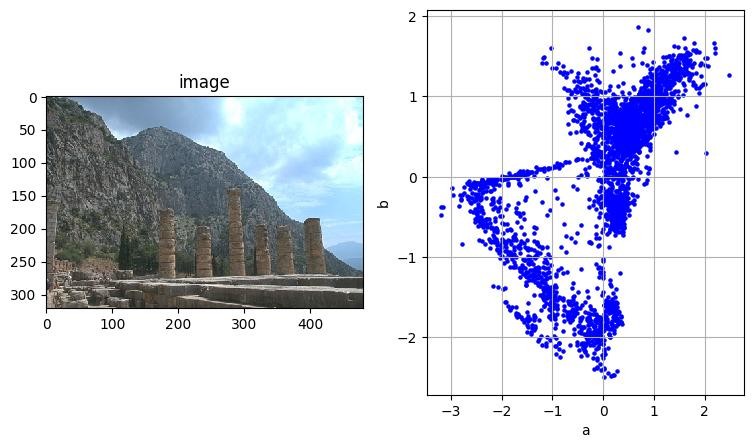

In [5]:
# image to use
img = imgdata[6]
gt  = gtdata[6]

# extract features, each row is a feature vector
Xo,Ytrue, L = getfeatures(img, gt)
print(Xo.shape)

# normalize features
scaler = preprocessing.StandardScaler()
X = scaler.fit_transform(Xo)

# view the image
plt.figure(figsize=(9,5))
plt.subplot(1,2,1)
plt.imshow(img, interpolation='nearest')
plt.title("image")

# view the features
plt.subplot(1,2,2)
#plt.scatter(X[:,0], X[:,1], c='b', s=5, edgecolor='')
plt.scatter(X[:,0], X[:,1], c='b', s=5, edgecolor=None)
plt.ylabel('b'); plt.xlabel('a'); plt.grid(True)

Here is the segmented image, with the segment labels shown as colors.  The goal is to recoever these labels using clustering.

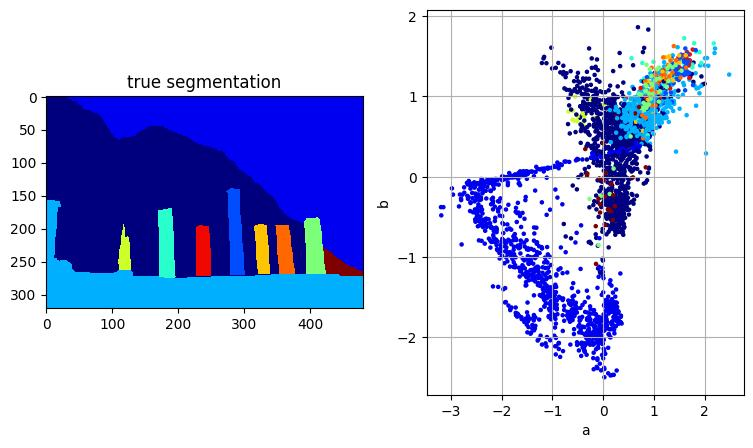

In [6]:
# view the image
plt.figure(figsize=(9,5))

plt.subplot(1,2,1)
plt.imshow(gt, interpolation='nearest', cmap='jet')
plt.title("true segmentation")

# view the features
plt.subplot(1,2,2)
plt.scatter(X[:,0], X[:,1], c=Ytrue, s=5, edgecolor=None, cmap='jet')
plt.ylabel('b'); plt.xlabel('a'); plt.grid(True)

Now use a clustering algorithm to group the data into **5** clusters.

In [7]:
# use K-means to cluster the color features into 5 clusters
kmeans = cluster.KMeans(n_clusters=5, random_state=123, n_init=10)
kmeans.fit(X)
Y = kmeans.predict(X)

Once you have the cluster labels (Y), use the below code to generate the segmentation image and view it.  You can also view the scatter plot with `showscatter`.

In [8]:
def showsegm(segm, img):
    "show a segmentation"

    # fill segmentation with colors from the image
    csegm = colorsegms(segm, img)

    # view the images, segmentation, and ground-truth
    plt.figure(figsize=(9,6))
    plt.subplot(2,2,1)
    plt.imshow(img, interpolation='nearest')
    plt.title('image')
    plt.subplot(2,2,2)
    plt.imshow(segm, interpolation='nearest', cmap='jet')
    plt.title('segmentation')
    plt.subplot(2,2,3)
    plt.imshow(csegm, interpolation='nearest')
    plt.title('segmentation w/ color')
    plt.subplot(2,2,4)
    plt.imshow(gt, interpolation='nearest', cmap='jet')
    plt.title("ground truth")

    return segm

def showscatter(X,Y):
    "show a scatter plot of clusters"

    if X.shape[1] == 2:
        plt.figure()
        plt.scatter(X[:,0], X[:,1], c=Y, s=5, edgecolor=None, cmap='jet')
        plt.grid(True)
        plt.xlabel('a')
        plt.ylabel('b')
    else:
        plt.figure(figsize=(9,9))

        plt.subplot(2,2,1)
        plt.scatter(X[:,0], X[:,1], c=Y, s=5, edgecolor=None, cmap='jet')
        plt.xlabel('a'); plt.ylabel('b'); plt.grid(True)

        plt.subplot(2,2,2)
        plt.scatter(X[:,2], X[:,3], c=Y, s=5, edgecolor=None, cmap='jet')
        plt.xlabel('x-pos'); plt.ylabel('y-pos'); plt.grid(True)

        plt.subplot(2,2,3)
        plt.scatter(X[:,2], X[:,0], c=Y, s=5, edgecolor=None, cmap='jet')
        plt.xlabel('x-pos'); plt.ylabel('a'); plt.grid(True)

        plt.subplot(2,2,4)
        plt.scatter(X[:,3], X[:,1], c=Y, s=5, edgecolor=None, cmap='jet')
        plt.xlabel('y-pos'); plt.ylabel('b'); plt.grid(True)

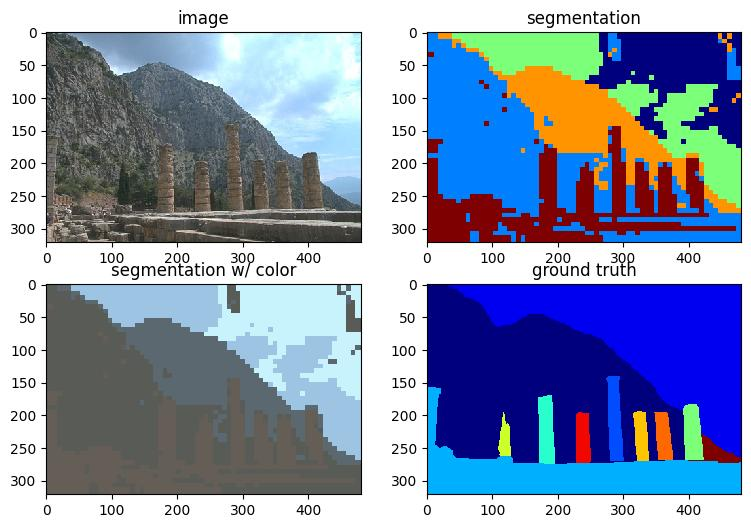

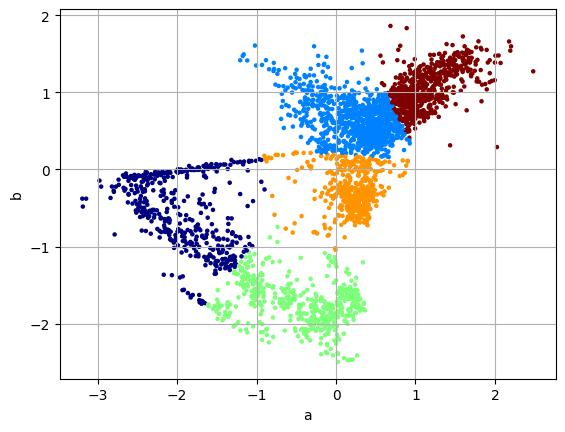

In [9]:
# convert cluster labels to a segmentation image
segm = labels2seg(Y, L)

# show the segmentation
showsegm(segm, img)

# show the scatter plot
showscatter(X,Y)

Next we evaluate the segmentation with the ground-truth provided by a human annotator.  We cannot just check that the cluster assignments for each pixel are the same, since the cluster indices can be permuted.  We will use the [Adjusted Rand Index (ARI)](https://en.wikipedia.org/wiki/Rand_index#Adjusted_Rand_index), which calculates how often a pair of pixels is assigned correctly to the same cluster or not.  Use the below code to calculate the [ARI](https://scikit-learn.org/stable/modules/clustering.html#adjusted-rand-score). Higher values are better, and the maximum value is 1.

In [10]:
# calculate ARI
ari = metrics.adjusted_rand_score(gt.flatten(), segm.flatten())
print("ARI =",ari)

ARI = 0.3850745518535788


Let us iterate K-means and Gaussian Mixture Models with different cluster number to get the best segmentation as measured by ARI.

In [11]:
Ks  = [2, 3, 4, 5, 6, 7, 8, 9, 10] #cluster numbers
models = [
   [cluster.KMeans(random_state=123, n_init=10), {'n_clusters':Ks}],
   [mixture.GaussianMixture(covariance_type='diag', random_state=444), {'n_components': Ks}],
  ]

results = []
for model, params in models:
    for param in model_selection.ParameterGrid(params):
        # fit the model with the current parameter setting
        clf = model.set_params(**param)
        clf.fit(X)
        Y = clf.predict(X)

        # convert cluster labels to a segmentation image and calculate ARI
        segm = labels2seg(Y, L)
        ari = metrics.adjusted_rand_score(gt.flatten(), segm.flatten())

        # save the result
        results.append({
            'name': type(model).__name__,
            'param': param,
            'Y': Y,
            'segm': segm,
            'ari': ari,
        })
        print(type(model).__name__, param, 'ARI =', ari)

KMeans {'n_clusters': 2} ARI = 0.4455613958415954
KMeans {'n_clusters': 3} ARI = 0.32369189131938003
KMeans {'n_clusters': 4} ARI = 0.5399433308656542
KMeans {'n_clusters': 5} ARI = 0.3850745518535788
KMeans {'n_clusters': 6} ARI = 0.33571310137222565
KMeans {'n_clusters': 7} ARI = 0.2582429952910636
KMeans {'n_clusters': 8} ARI = 0.30528936361331416
KMeans {'n_clusters': 9} ARI = 0.2806809986239099
KMeans {'n_clusters': 10} ARI = 0.25813112543681194
GaussianMixture {'n_components': 2} ARI = 0.3653564714017668
GaussianMixture {'n_components': 3} ARI = 0.332372951913529
GaussianMixture {'n_components': 4} ARI = 0.5385142979415881
GaussianMixture {'n_components': 5} ARI = 0.3421878249461606
GaussianMixture {'n_components': 6} ARI = 0.2916855597360064
GaussianMixture {'n_components': 7} ARI = 0.2610152415756034
GaussianMixture {'n_components': 8} ARI = 0.23506418557567338
GaussianMixture {'n_components': 9} ARI = 0.2726367909067004
GaussianMixture {'n_components': 10} ARI = 0.261496373903

In [12]:
for L in results:
    print(L['name'])
    print(L['param'])
    print(L['ari'])

KMeans
{'n_clusters': 2}
0.4455613958415954
KMeans
{'n_clusters': 3}
0.32369189131938003
KMeans
{'n_clusters': 4}
0.5399433308656542
KMeans
{'n_clusters': 5}
0.3850745518535788
KMeans
{'n_clusters': 6}
0.33571310137222565
KMeans
{'n_clusters': 7}
0.2582429952910636
KMeans
{'n_clusters': 8}
0.30528936361331416
KMeans
{'n_clusters': 9}
0.2806809986239099
KMeans
{'n_clusters': 10}
0.25813112543681194
GaussianMixture
{'n_components': 2}
0.3653564714017668
GaussianMixture
{'n_components': 3}
0.332372951913529
GaussianMixture
{'n_components': 4}
0.5385142979415881
GaussianMixture
{'n_components': 5}
0.3421878249461606
GaussianMixture
{'n_components': 6}
0.2916855597360064
GaussianMixture
{'n_components': 7}
0.2610152415756034
GaussianMixture
{'n_components': 8}
0.23506418557567338
GaussianMixture
{'n_components': 9}
0.2726367909067004
GaussianMixture
{'n_components': 10}
0.26149637390321356


----
KMeans
{'n_clusters': 2}


<Figure size 640x480 with 0 Axes>

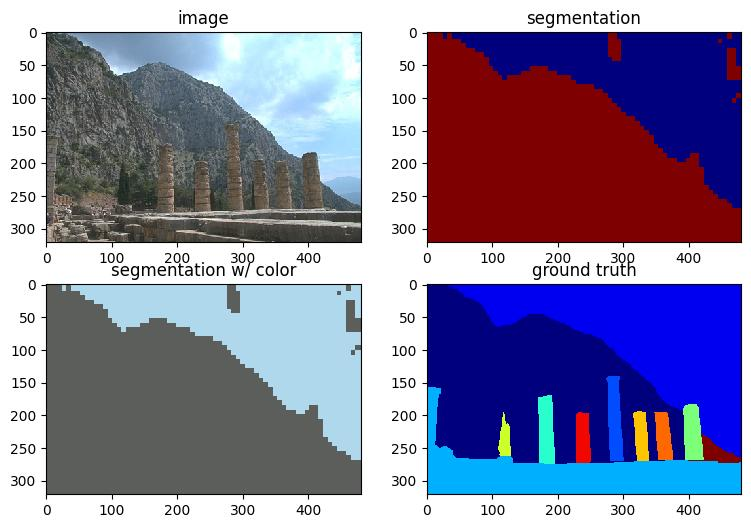

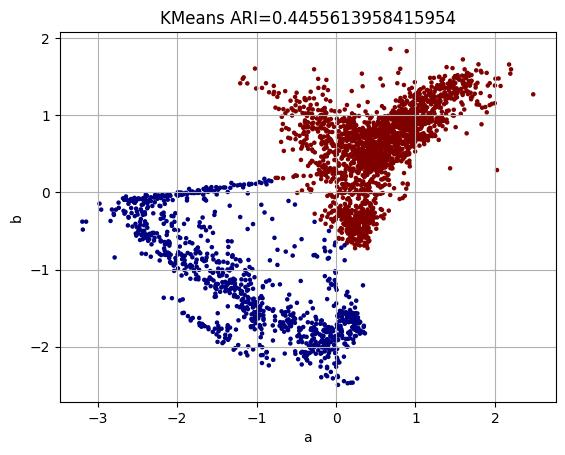

----
KMeans
{'n_clusters': 3}


<Figure size 640x480 with 0 Axes>

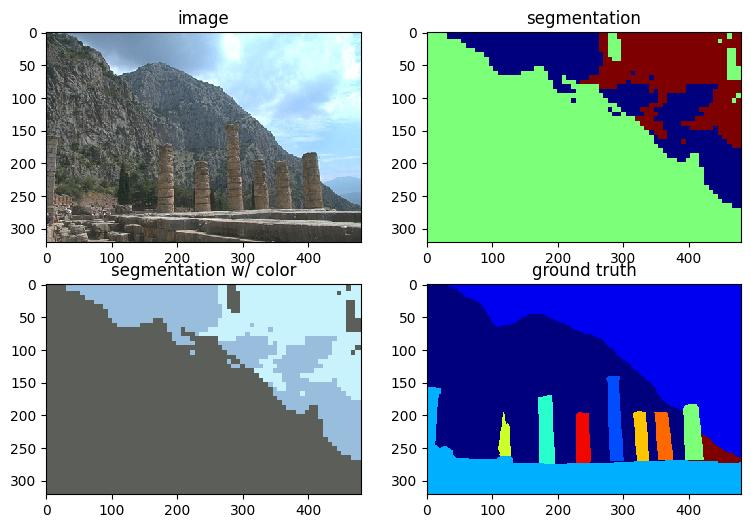

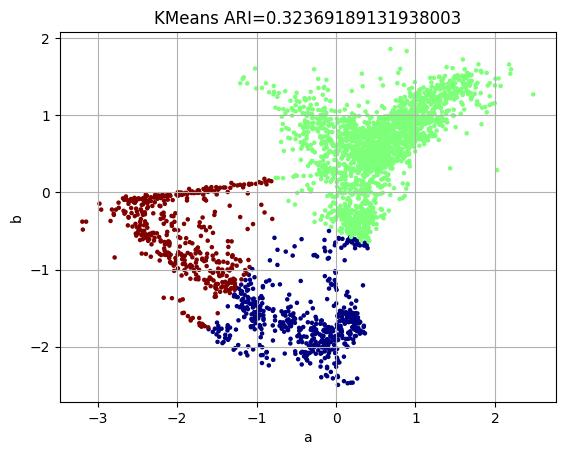

----
KMeans
{'n_clusters': 4}


<Figure size 640x480 with 0 Axes>

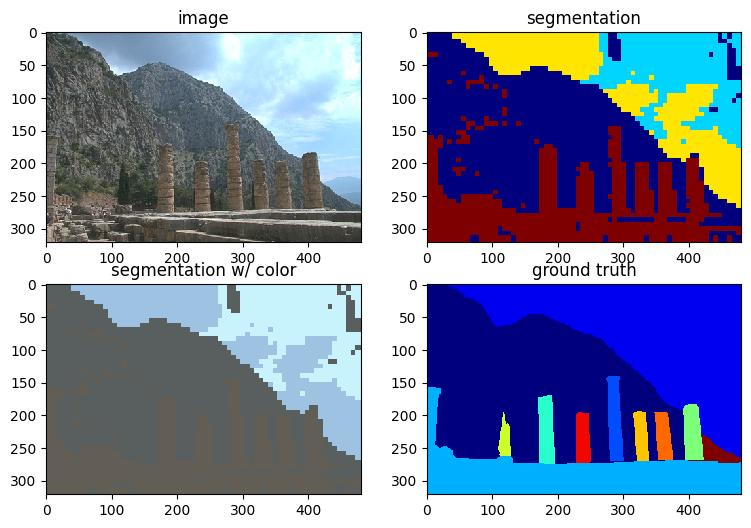

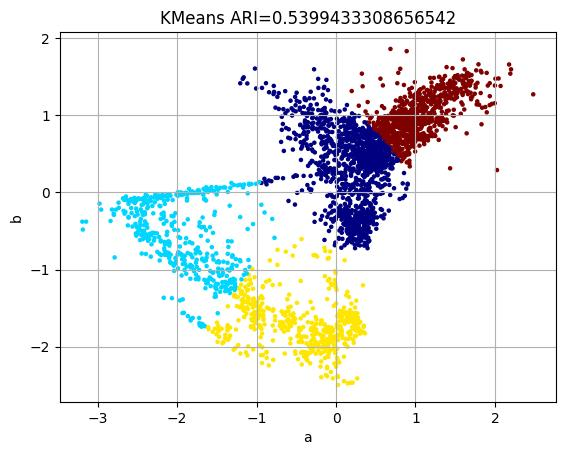

----
KMeans
{'n_clusters': 5}


<Figure size 640x480 with 0 Axes>

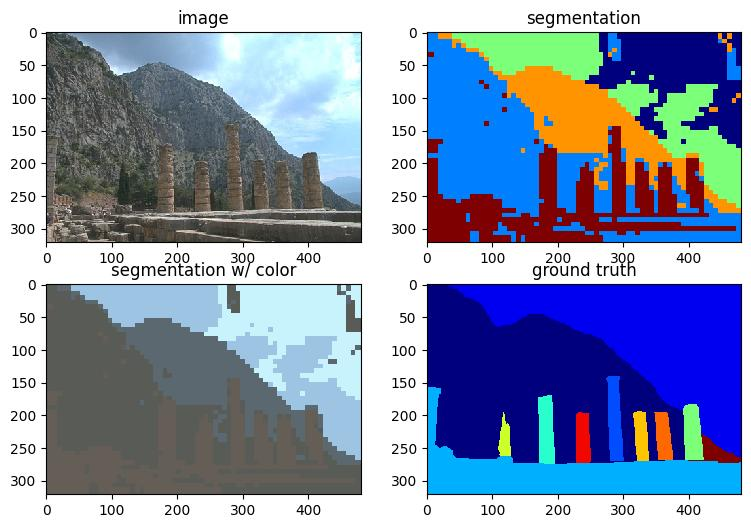

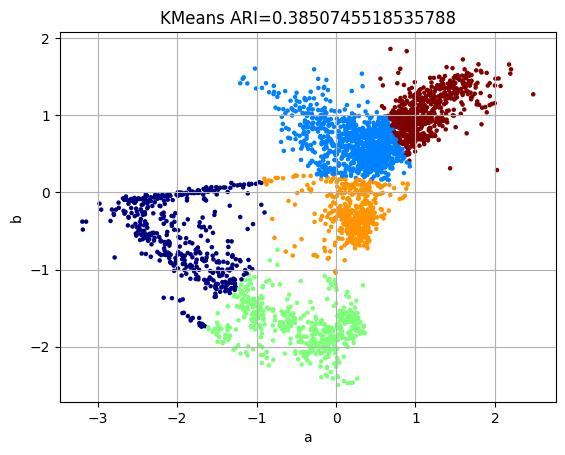

----
KMeans
{'n_clusters': 6}


<Figure size 640x480 with 0 Axes>

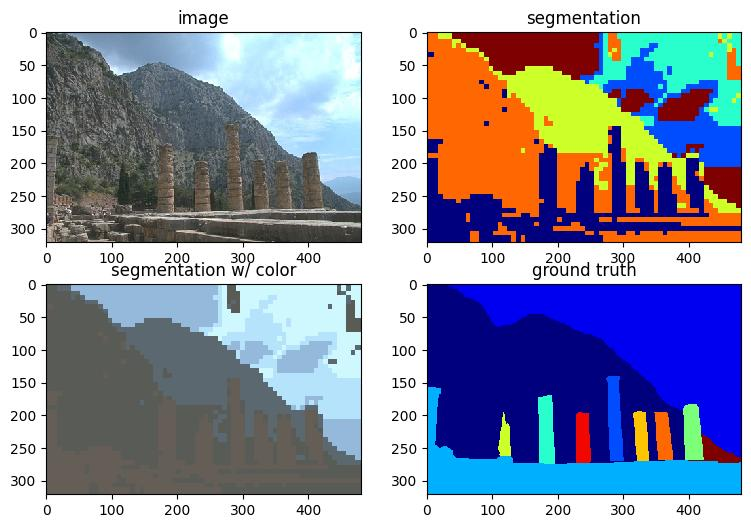

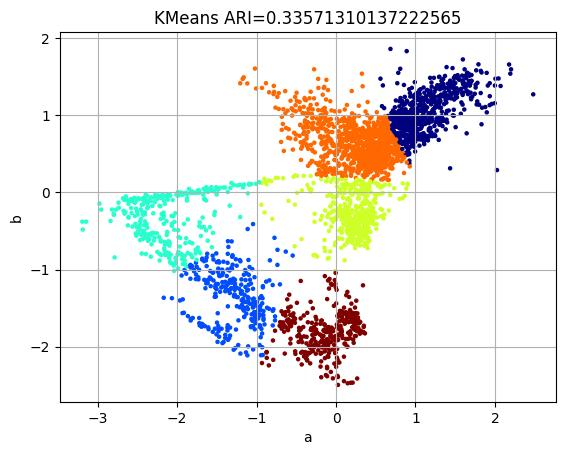

----
KMeans
{'n_clusters': 7}


<Figure size 640x480 with 0 Axes>

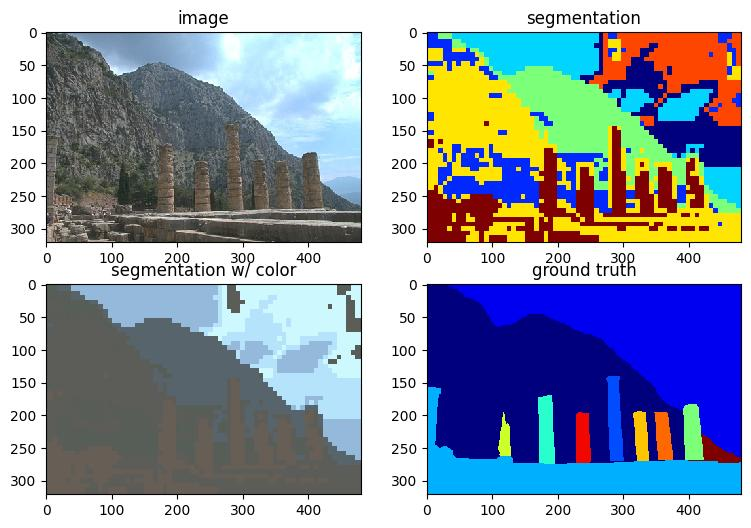

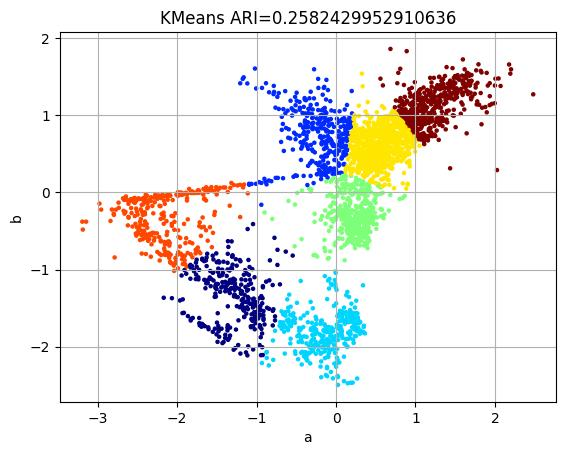

----
KMeans
{'n_clusters': 8}


<Figure size 640x480 with 0 Axes>

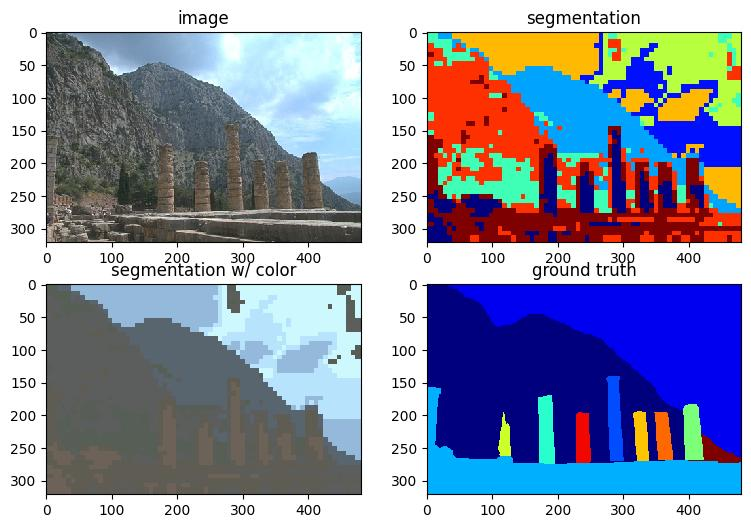

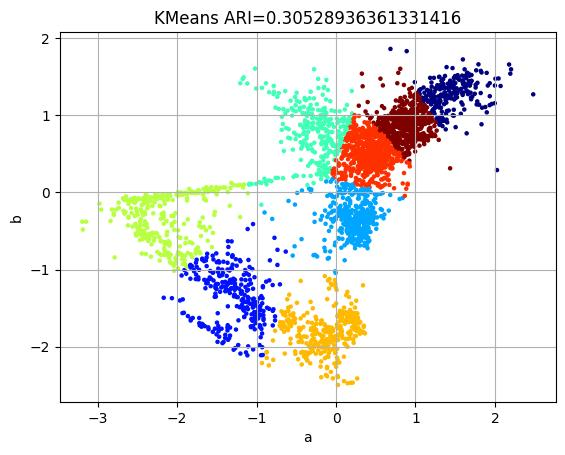

----
KMeans
{'n_clusters': 9}


<Figure size 640x480 with 0 Axes>

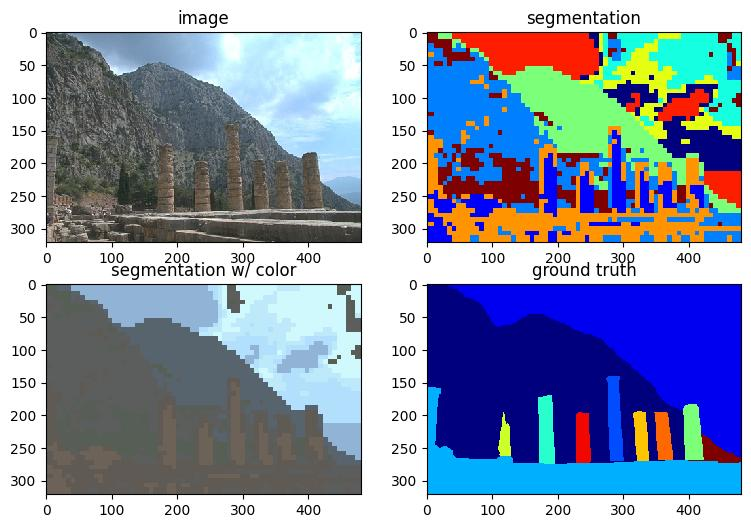

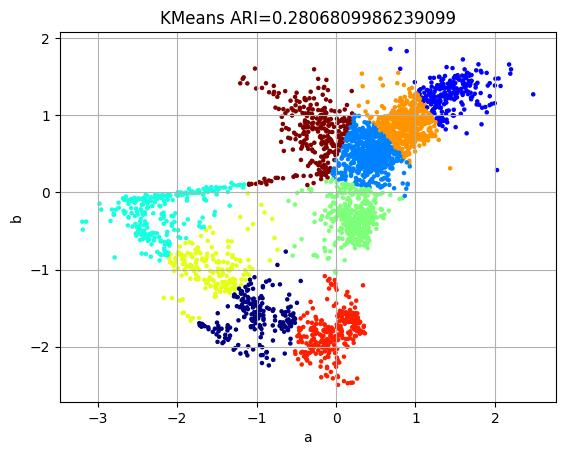

----
KMeans
{'n_clusters': 10}


<Figure size 640x480 with 0 Axes>

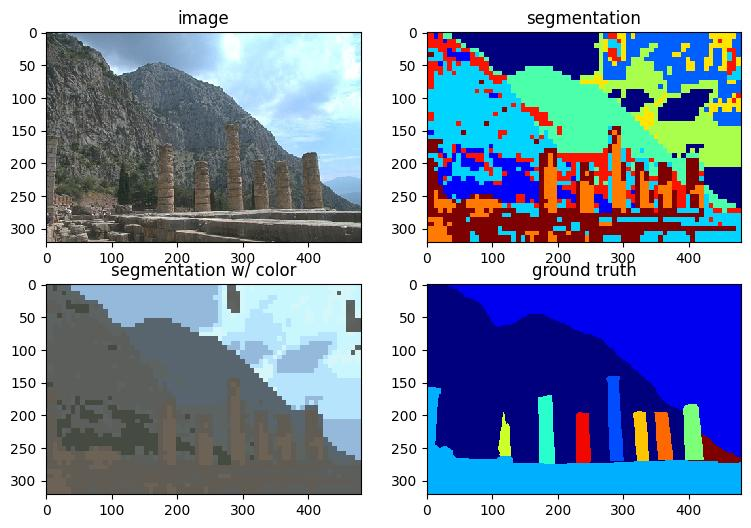

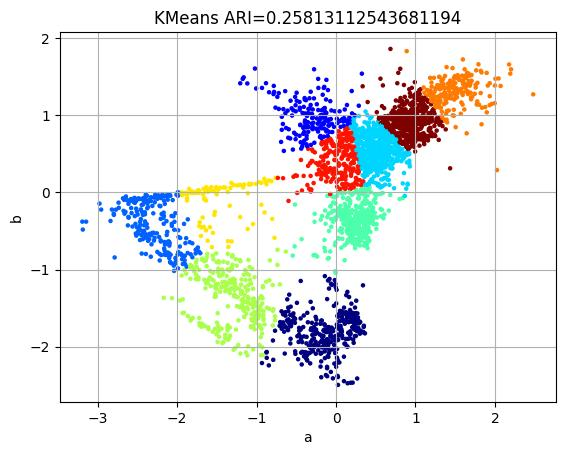

----
GaussianMixture
{'n_components': 2}


<Figure size 640x480 with 0 Axes>

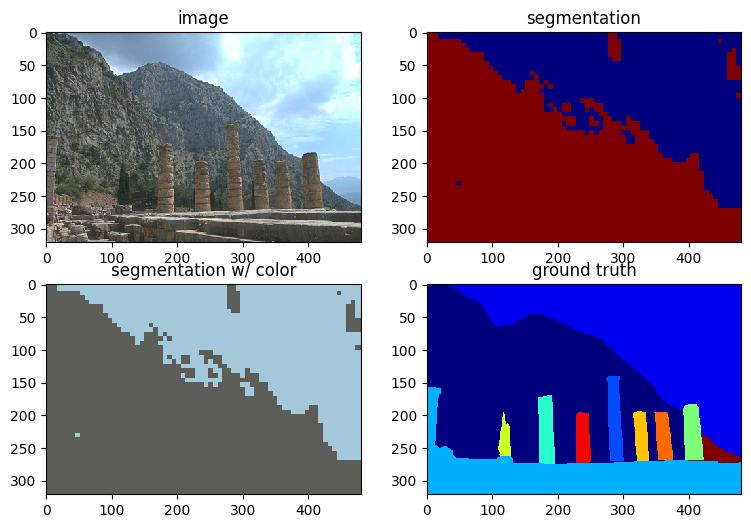

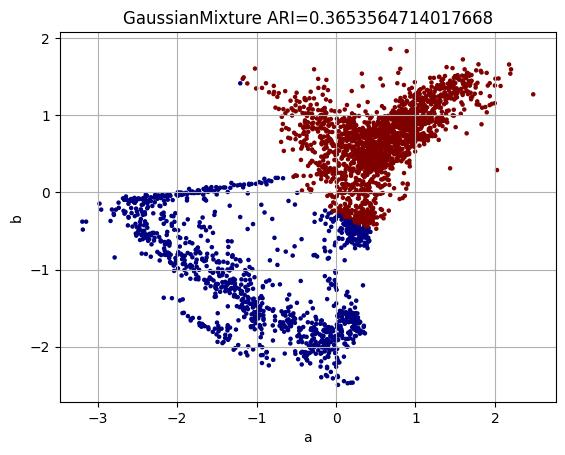

----
GaussianMixture
{'n_components': 3}


<Figure size 640x480 with 0 Axes>

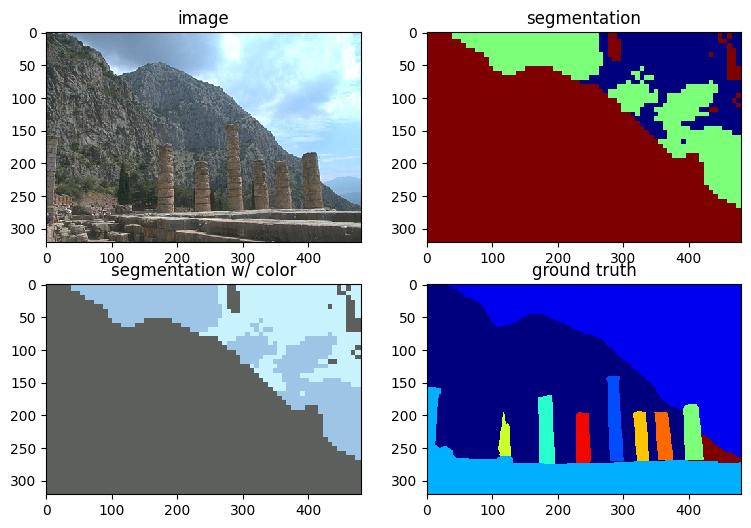

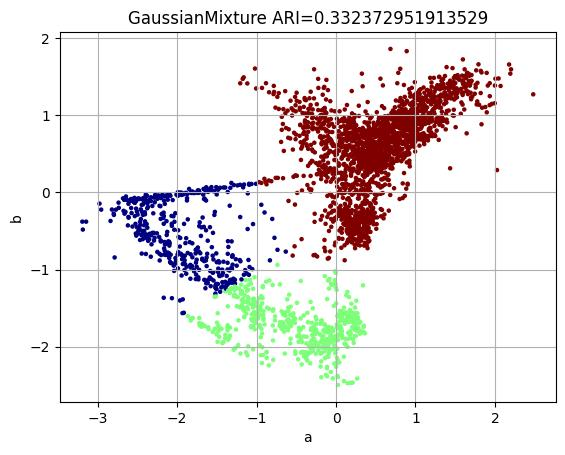

----
GaussianMixture
{'n_components': 4}


<Figure size 640x480 with 0 Axes>

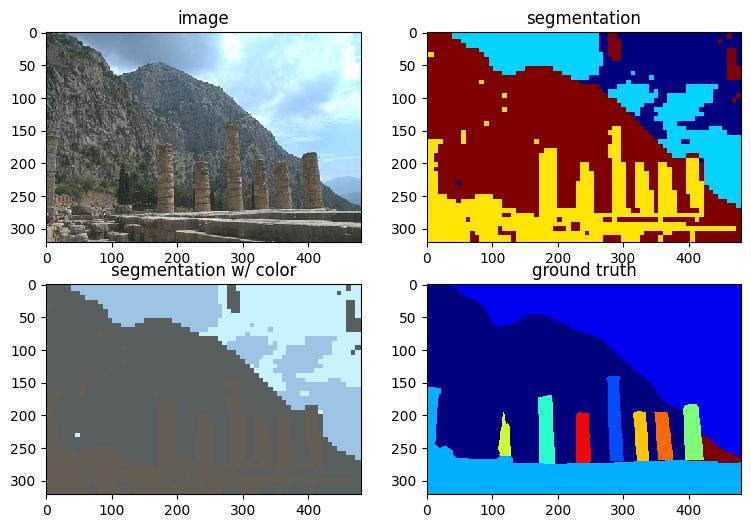

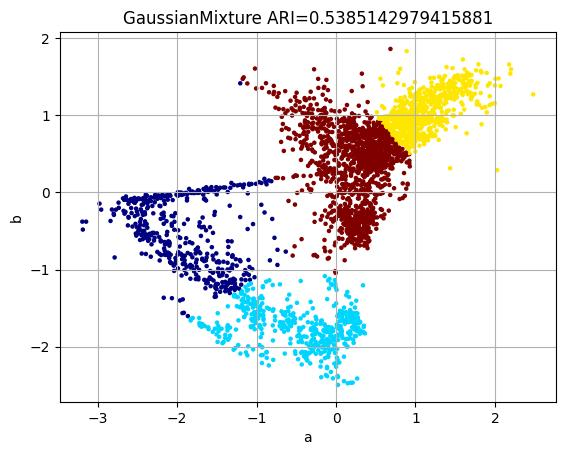

----
GaussianMixture
{'n_components': 5}


<Figure size 640x480 with 0 Axes>

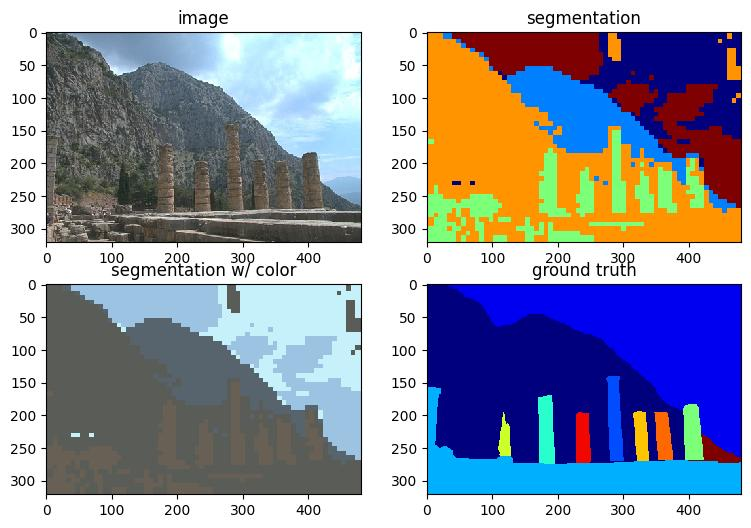

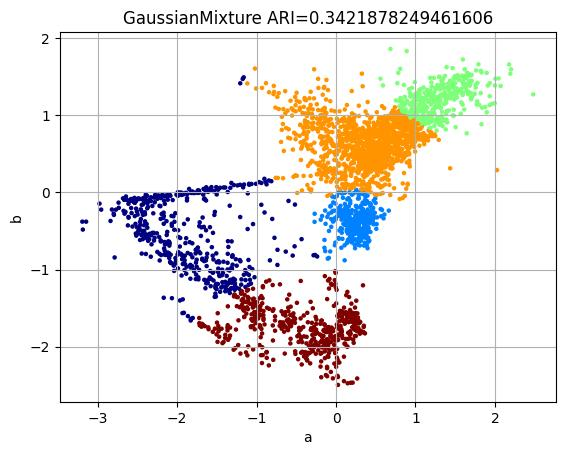

----
GaussianMixture
{'n_components': 6}


<Figure size 640x480 with 0 Axes>

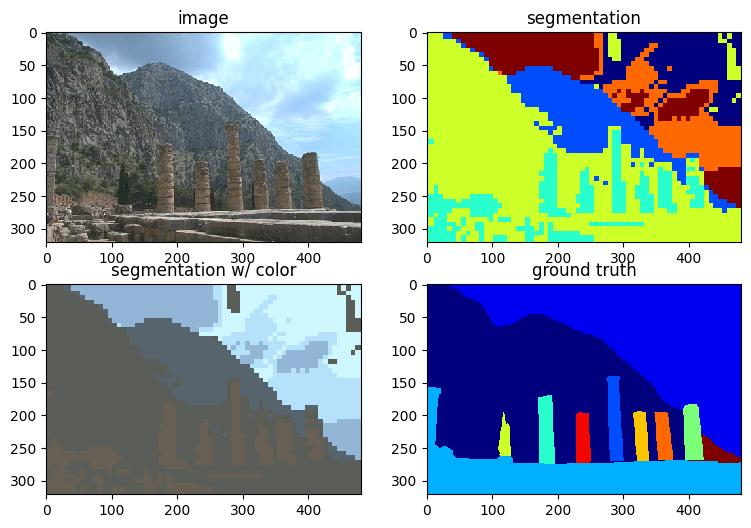

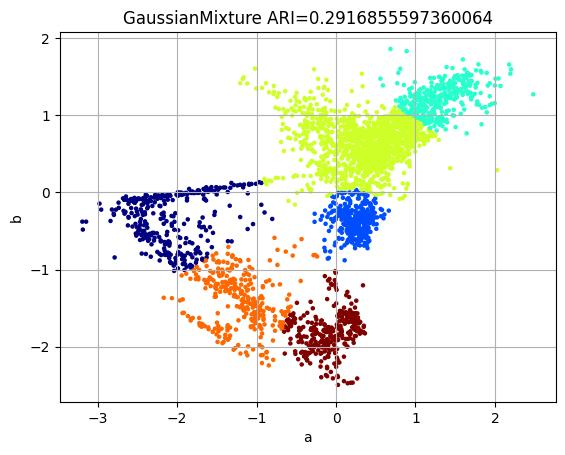

----
GaussianMixture
{'n_components': 7}


<Figure size 640x480 with 0 Axes>

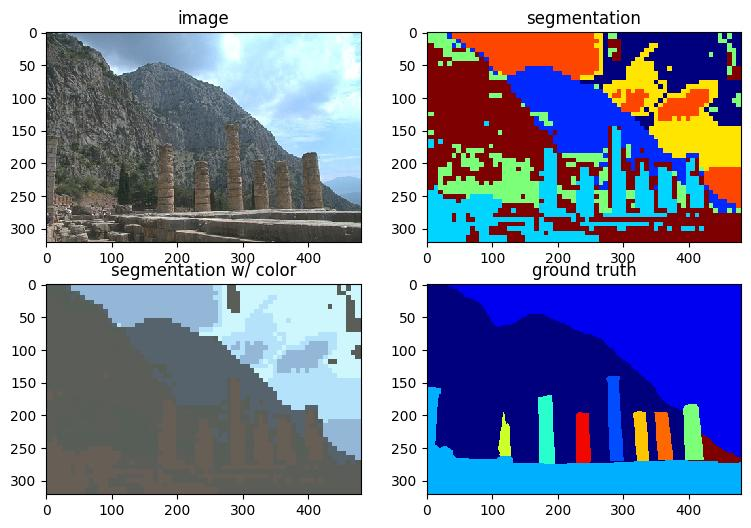

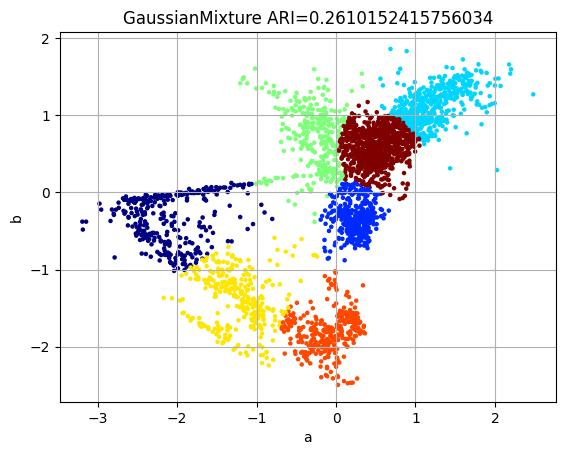

----
GaussianMixture
{'n_components': 8}


<Figure size 640x480 with 0 Axes>

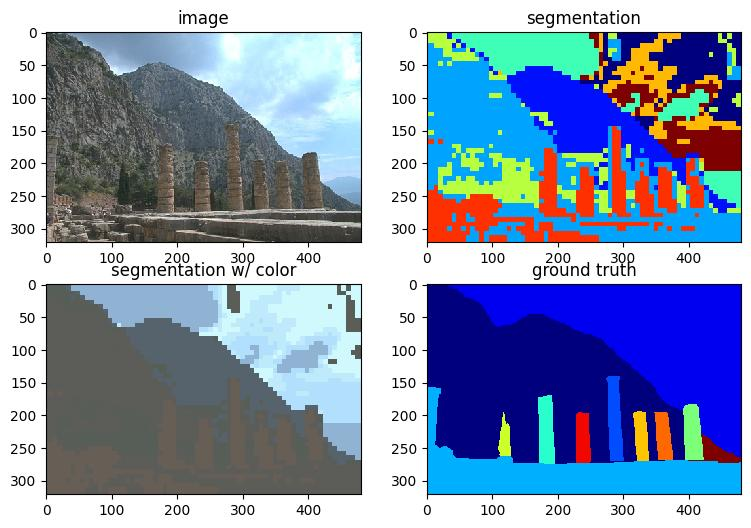

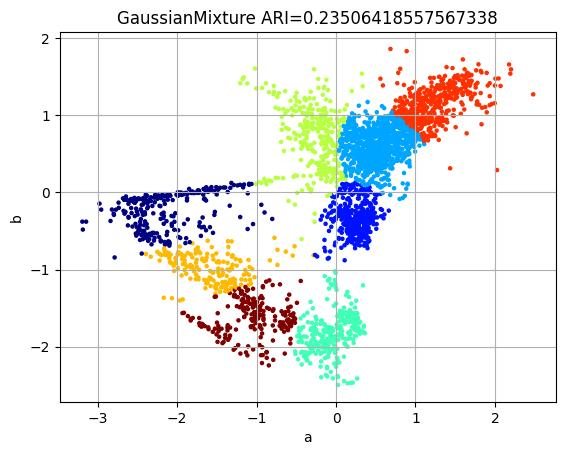

----
GaussianMixture
{'n_components': 9}


<Figure size 640x480 with 0 Axes>

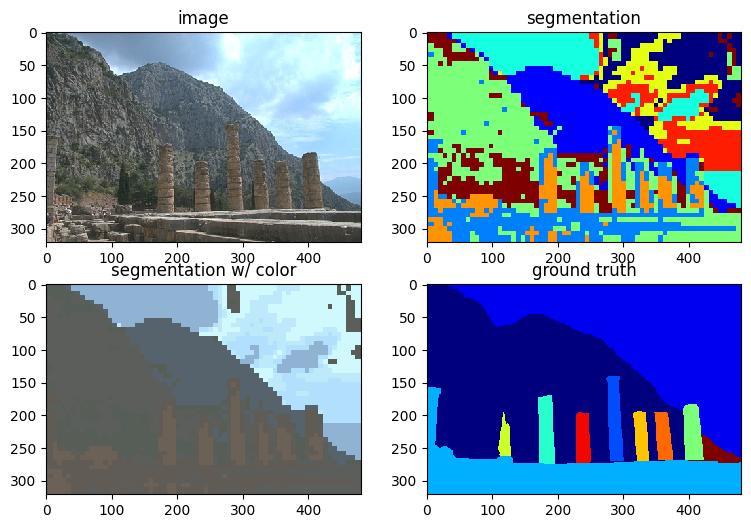

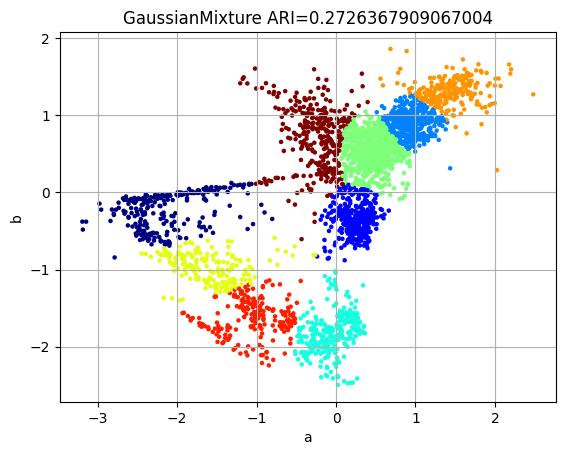

----
GaussianMixture
{'n_components': 10}


<Figure size 640x480 with 0 Axes>

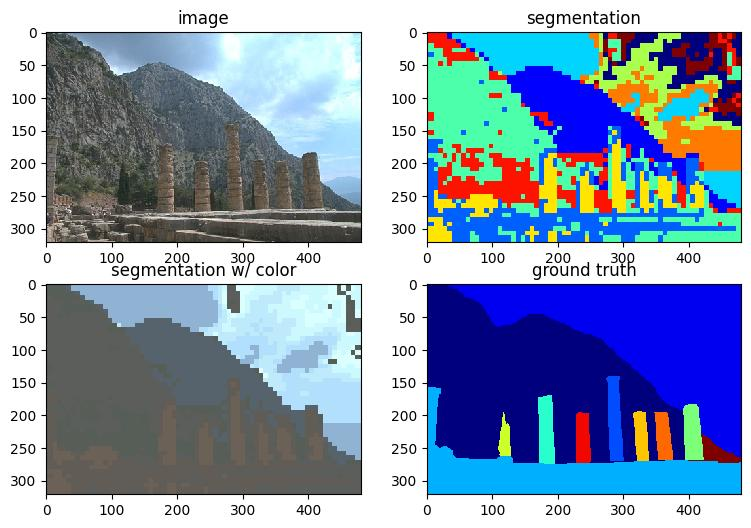

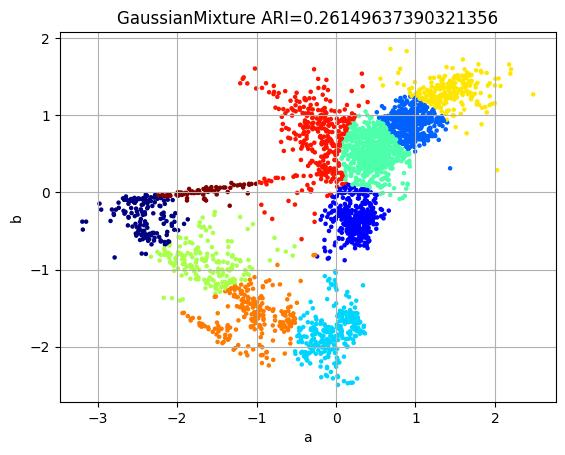

In [13]:
for L in results:
    print('----')
    print(L['name'])
    print(L['param'])

    plt.figure()
    # show the segmentation
    showsegm(L['segm'], img)

    # show the scatter plot
    showscatter(X,L['Y'])
    plt.title(L['name'] + " ARI=" + str(L['ari']))
    plt.show()

## 3. Color and Position Features
You may notice that the segmentation is not spatially smooth. There are some "loner" pixels that are not the same cluster as the surrounding pixels.  This is because we are only clustering color.  One way to fix this is to include the (x,y) coordinate of the pixel as part of the feature vector.  This way, clusters will have pixels that are spatially close together.

The below code extracts a 4-dimensional feature vector, where the first 2 features are the color channels and the last 2 features are the position.

In [14]:
# extract features with location
Xo,Ytrue,L = getfeatures(img, gt, use_loc=True)
print(Xo.shape)

# normalize features
scaler = preprocessing.StandardScaler()
X = scaler.fit_transform(Xo)

# rescale position features
# larger values emphasize clustering by position more
X[:,2:4] *= 0.5

(3060, 4)


Here are plots of the 4 features.

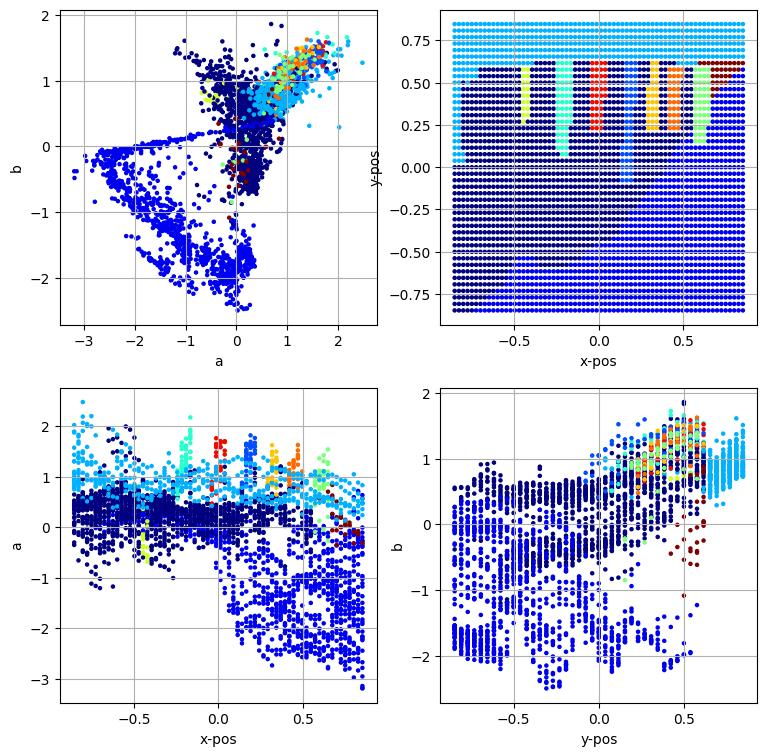

In [15]:
showscatter(X, Ytrue)

Run clustering algorithms on the 4-dimensional data.  Try different algorithms and parameters to get the best ARI.

In [16]:
# try more algorithms on the 4-dim (color + position) features
Ks = [2, 3, 4, 5, 6, 7, 8, 9, 10]
models = [
    [cluster.KMeans(random_state=123, n_init=10), {'n_clusters': Ks}],
    [mixture.GaussianMixture(covariance_type='diag', random_state=444), {'n_components': Ks}],
    [mixture.GaussianMixture(covariance_type='full', random_state=444), {'n_components': Ks}],
    [cluster.AgglomerativeClustering(linkage='ward'), {'n_clusters': Ks}],
]

results2 = []
for model, params in models:
    for param in model_selection.ParameterGrid(params):
        # AgglomerativeClustering has no predict(), so use fit_predict for all
        clf = model.set_params(**param)
        Y = clf.fit_predict(X)

        segm = labels2seg(Y, L)
        ari = metrics.adjusted_rand_score(gt.flatten(), segm.flatten())

        # add covariance type to the name so the two GMMs are distinguishable
        name = type(model).__name__
        if hasattr(model, 'covariance_type'):
            name += ' (' + model.covariance_type + ')'

        results2.append({'name': name, 'param': param, 'Y': Y, 'segm': segm, 'ari': ari})
        print(name, param, 'ARI =', ari)

# also try DBSCAN with a few eps values (noise points get label -1)
for eps in [0.2, 0.3, 0.5, 1.0]:
    Y = cluster.DBSCAN(eps=eps).fit_predict(X)
    segm = labels2seg(Y, L)
    ari = metrics.adjusted_rand_score(gt.flatten(), segm.flatten())
    ncl = len(set(Y)) - (1 if -1 in Y else 0)
    results2.append({'name': 'DBSCAN', 'param': {'eps': eps}, 'Y': Y, 'segm': segm, 'ari': ari})
    print('DBSCAN', {'eps': eps}, '(%d clusters)' % ncl, 'ARI =', ari)

KMeans {'n_clusters': 2} ARI = 0.44781486354811967
KMeans {'n_clusters': 3} ARI = 0.24556108276548338
KMeans {'n_clusters': 4} ARI = 0.6017544381630745
KMeans {'n_clusters': 5} ARI = 0.44457681067512156
KMeans {'n_clusters': 6} ARI = 0.39828038720541536
KMeans {'n_clusters': 7} ARI = 0.3258519438495901
KMeans {'n_clusters': 8} ARI = 0.3165439660625275
KMeans {'n_clusters': 9} ARI = 0.29014396131796877
KMeans {'n_clusters': 10} ARI = 0.2746453493026586
GaussianMixture (diag) {'n_components': 2} ARI = 0.3340645956503333
GaussianMixture (diag) {'n_components': 3} ARI = 0.40894310894106517
GaussianMixture (diag) {'n_components': 4} ARI = 0.4723956470320907
GaussianMixture (diag) {'n_components': 5} ARI = 0.32602694899559825
GaussianMixture (diag) {'n_components': 6} ARI = 0.2816100118141423
GaussianMixture (diag) {'n_components': 7} ARI = 0.3326158808126148
GaussianMixture (diag) {'n_components': 8} ARI = 0.3577703586838155
GaussianMixture (diag) {'n_components': 9} ARI = 0.344495724224148

In [17]:
for L in results2:
    print(L['name'])
    print(L['param'])
    print(L['ari'])

KMeans
{'n_clusters': 2}
0.44781486354811967
KMeans
{'n_clusters': 3}
0.24556108276548338
KMeans
{'n_clusters': 4}
0.6017544381630745
KMeans
{'n_clusters': 5}
0.44457681067512156
KMeans
{'n_clusters': 6}
0.39828038720541536
KMeans
{'n_clusters': 7}
0.3258519438495901
KMeans
{'n_clusters': 8}
0.3165439660625275
KMeans
{'n_clusters': 9}
0.29014396131796877
KMeans
{'n_clusters': 10}
0.2746453493026586
GaussianMixture (diag)
{'n_components': 2}
0.3340645956503333
GaussianMixture (diag)
{'n_components': 3}
0.40894310894106517
GaussianMixture (diag)
{'n_components': 4}
0.4723956470320907
GaussianMixture (diag)
{'n_components': 5}
0.32602694899559825
GaussianMixture (diag)
{'n_components': 6}
0.2816100118141423
GaussianMixture (diag)
{'n_components': 7}
0.3326158808126148
GaussianMixture (diag)
{'n_components': 8}
0.3577703586838155
GaussianMixture (diag)
{'n_components': 9}
0.34449572422414876
GaussianMixture (diag)
{'n_components': 10}
0.31702313054081727
GaussianMixture (full)
{'n_componen

------
KMeans
{'n_clusters': 2}


<Figure size 640x480 with 0 Axes>

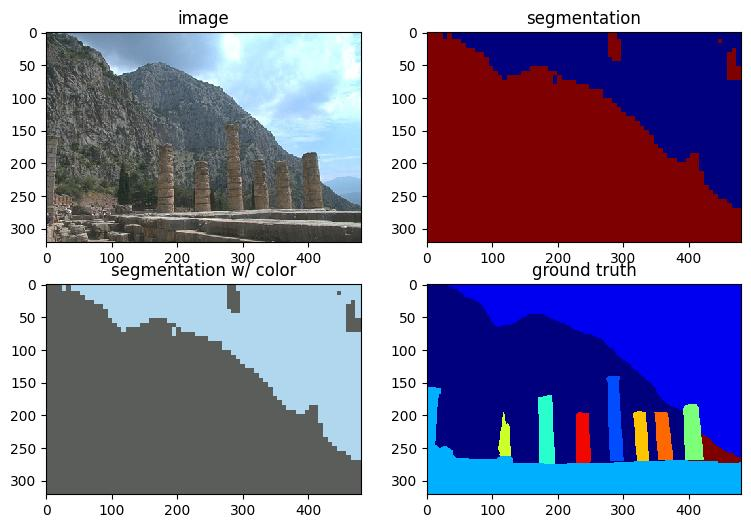

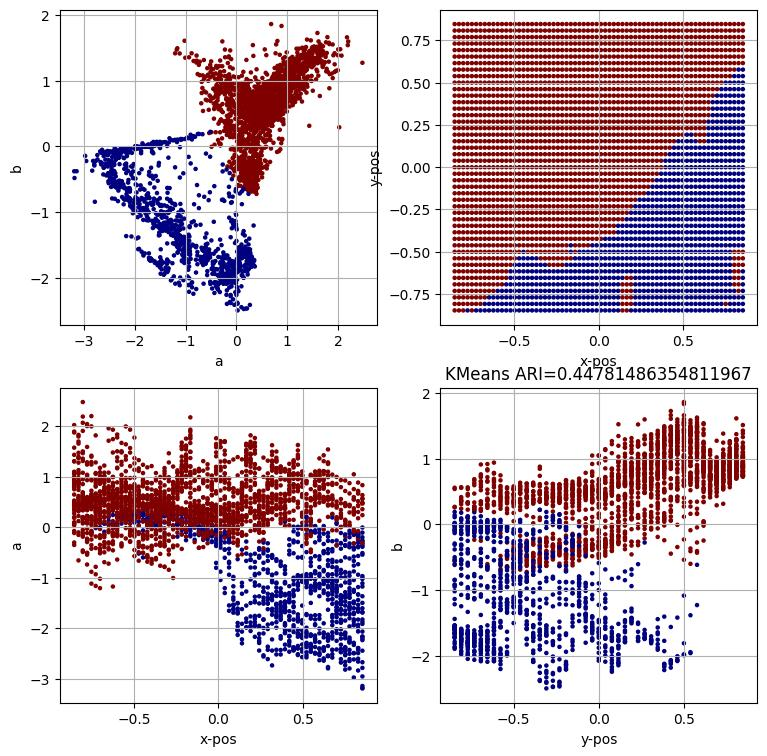

------
KMeans
{'n_clusters': 3}


<Figure size 640x480 with 0 Axes>

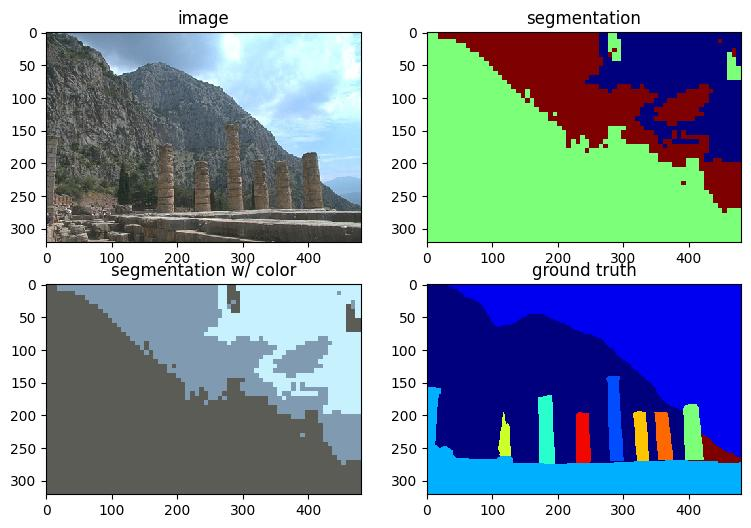

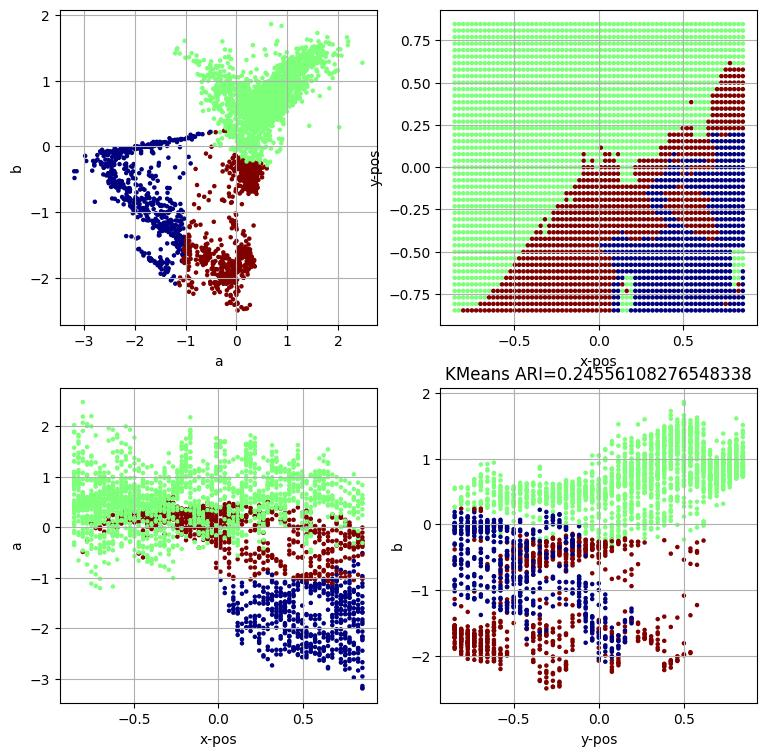

------
KMeans
{'n_clusters': 4}


<Figure size 640x480 with 0 Axes>

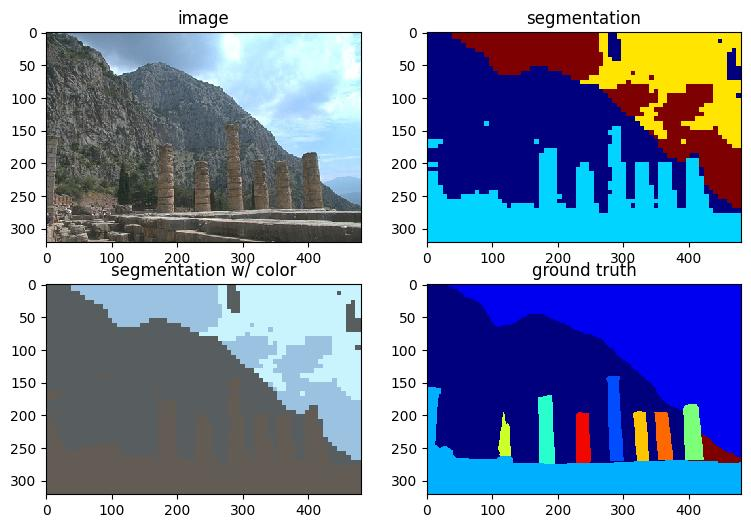

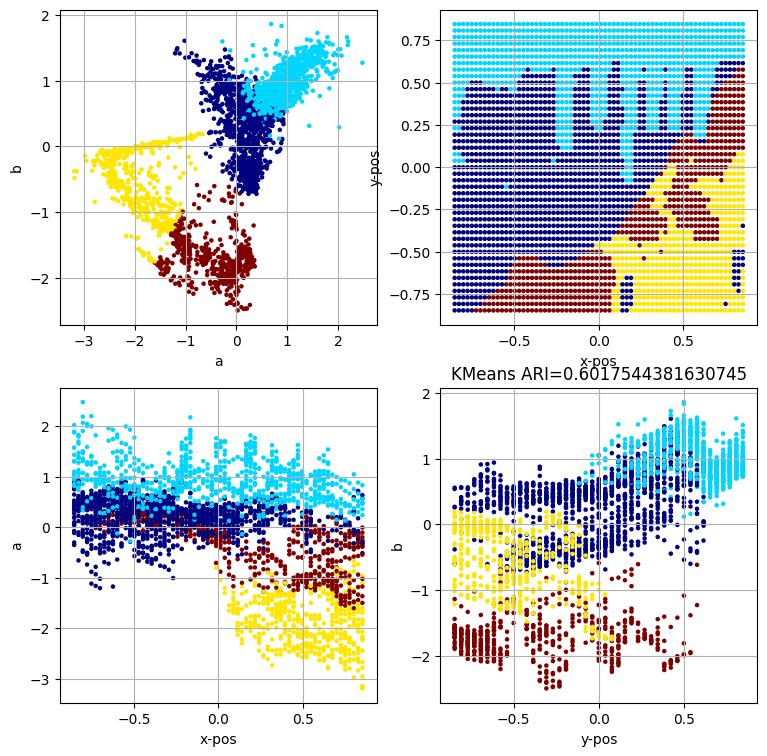

------
KMeans
{'n_clusters': 5}


<Figure size 640x480 with 0 Axes>

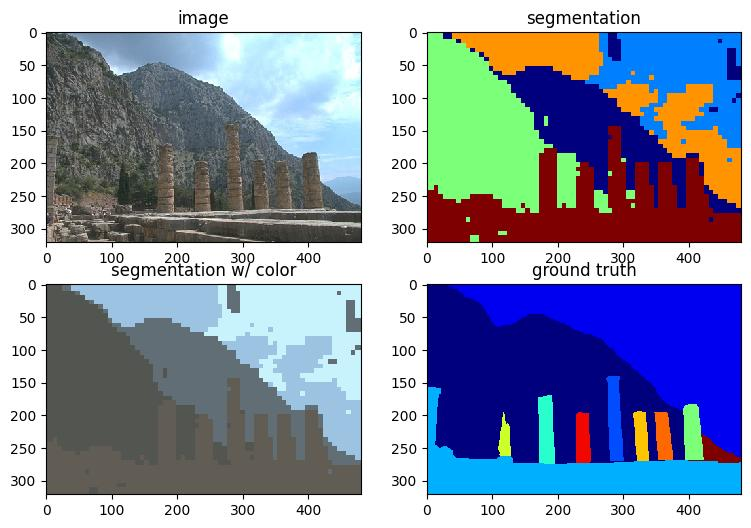

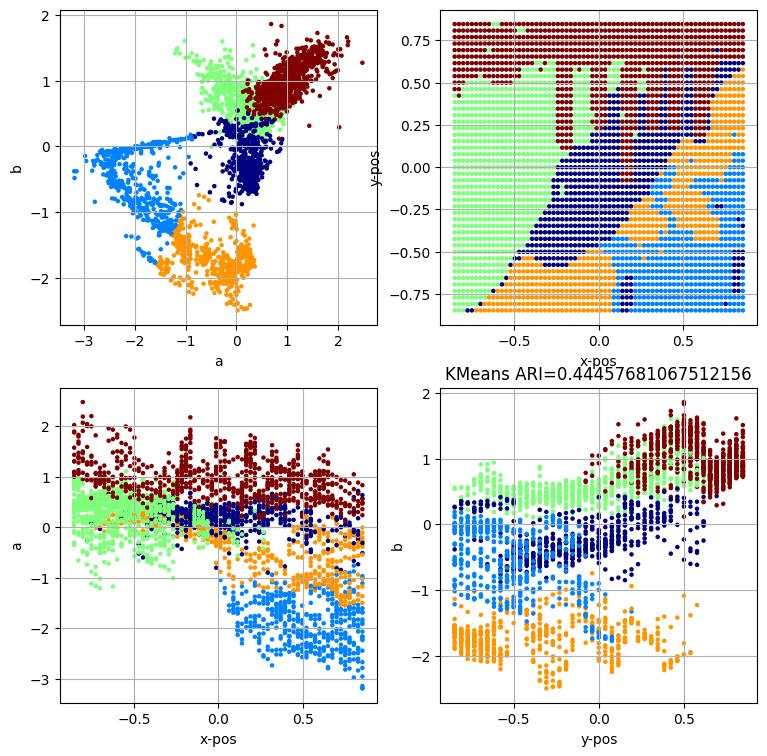

------
KMeans
{'n_clusters': 6}


<Figure size 640x480 with 0 Axes>

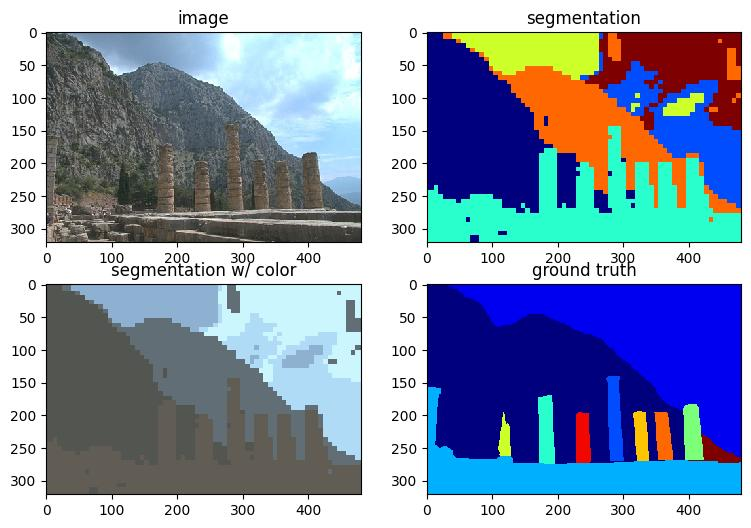

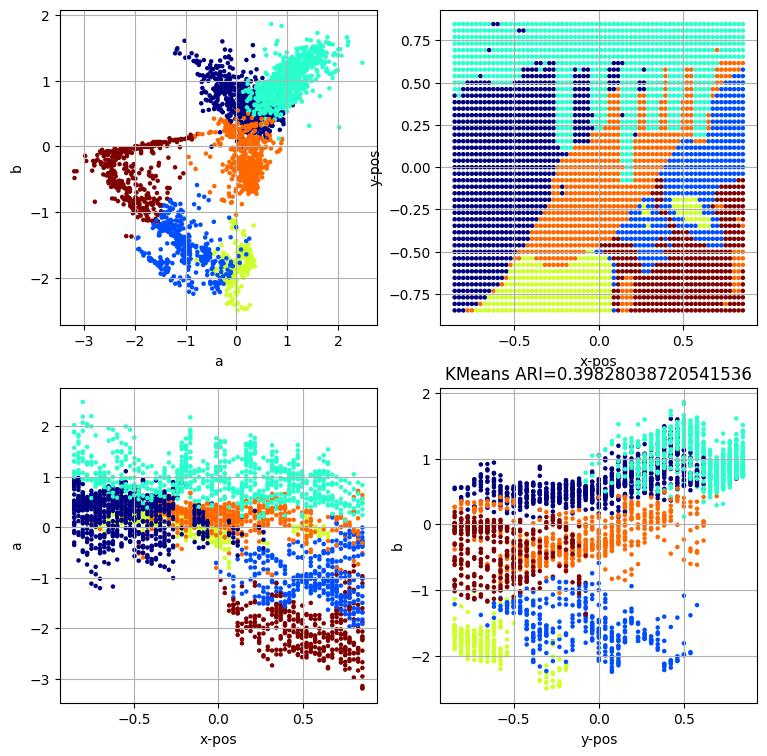

------
KMeans
{'n_clusters': 7}


<Figure size 640x480 with 0 Axes>

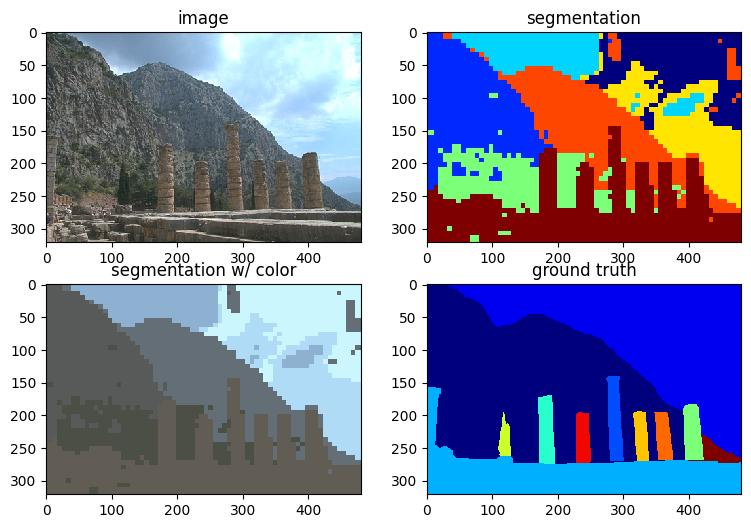

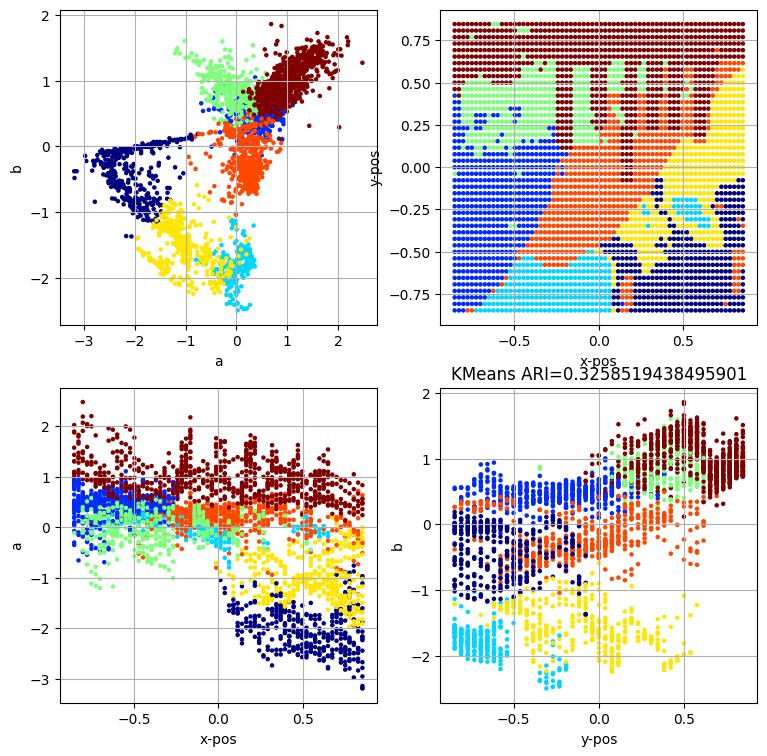

------
KMeans
{'n_clusters': 8}


<Figure size 640x480 with 0 Axes>

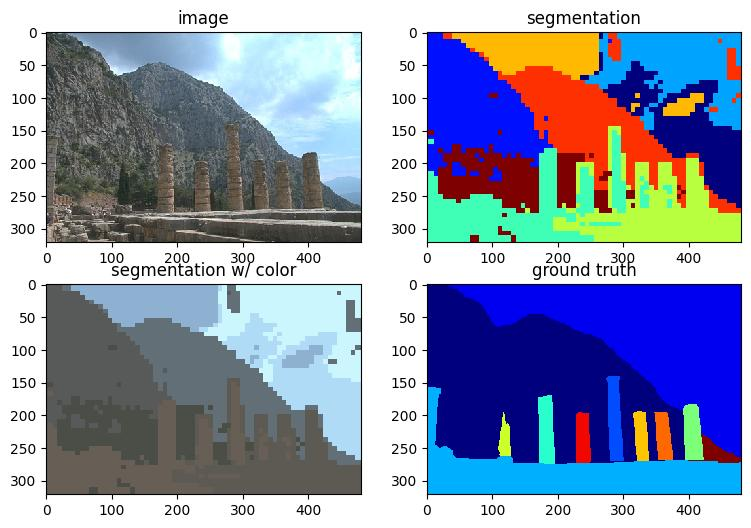

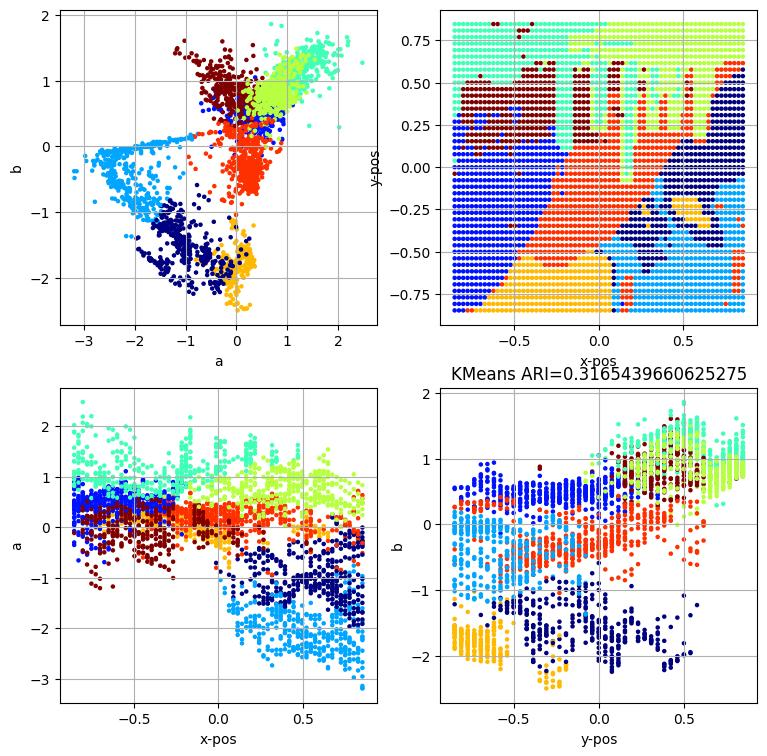

------
KMeans
{'n_clusters': 9}


<Figure size 640x480 with 0 Axes>

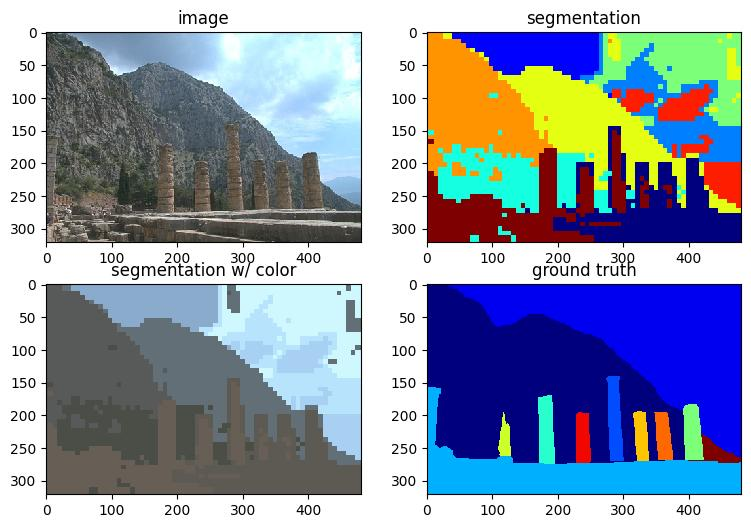

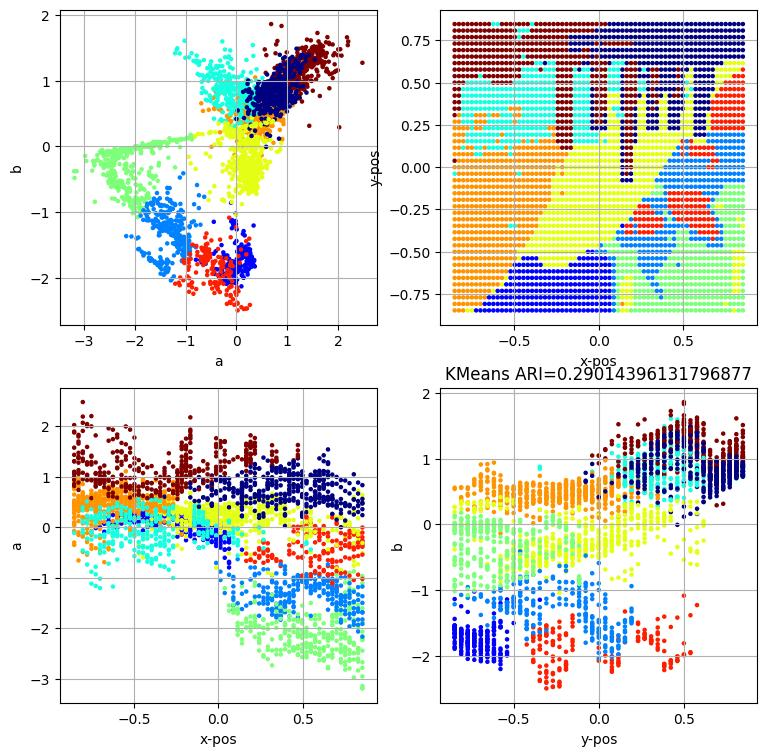

------
KMeans
{'n_clusters': 10}


<Figure size 640x480 with 0 Axes>

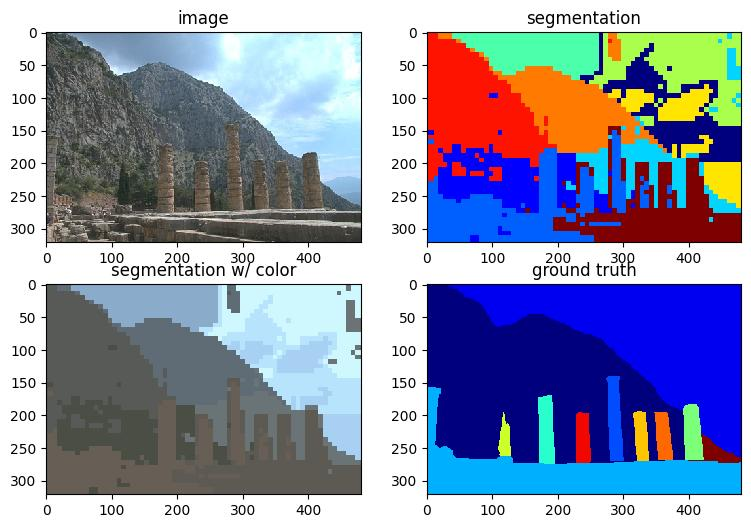

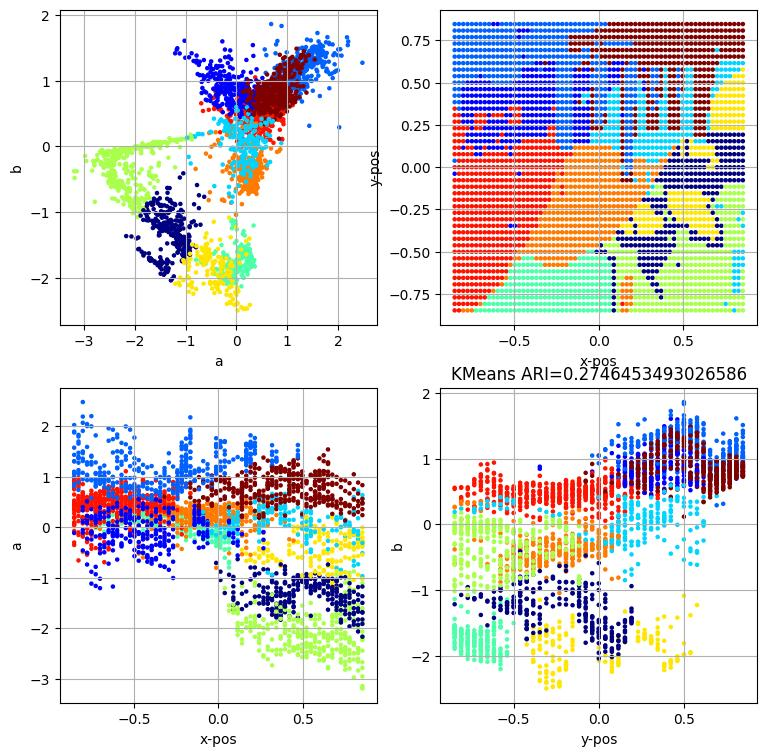

------
GaussianMixture (diag)
{'n_components': 2}


<Figure size 640x480 with 0 Axes>

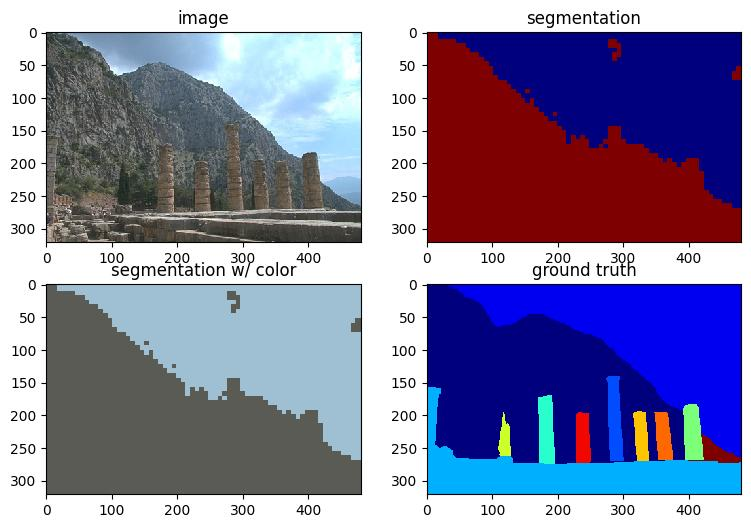

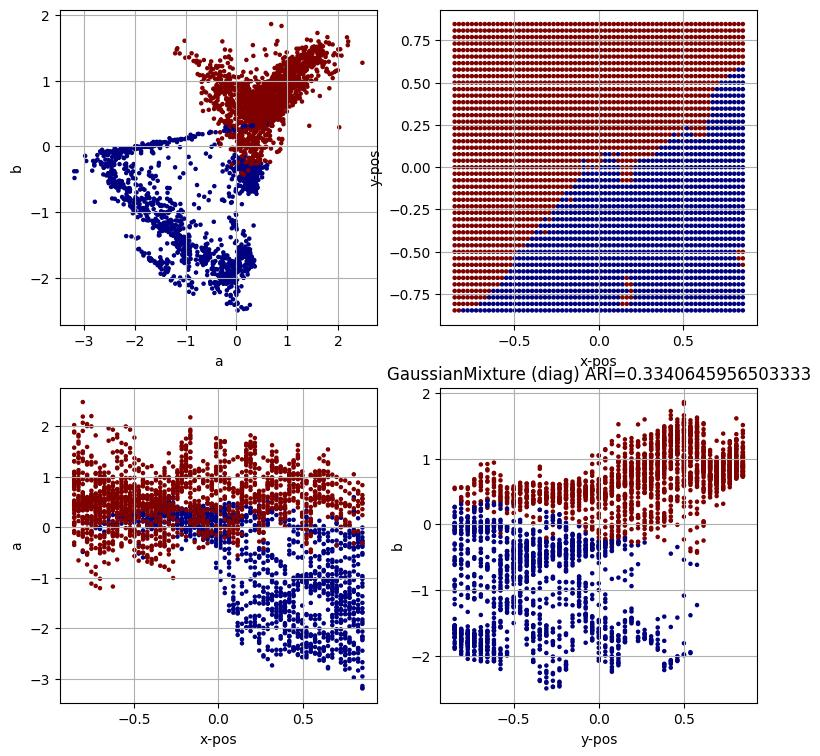

------
GaussianMixture (diag)
{'n_components': 3}


<Figure size 640x480 with 0 Axes>

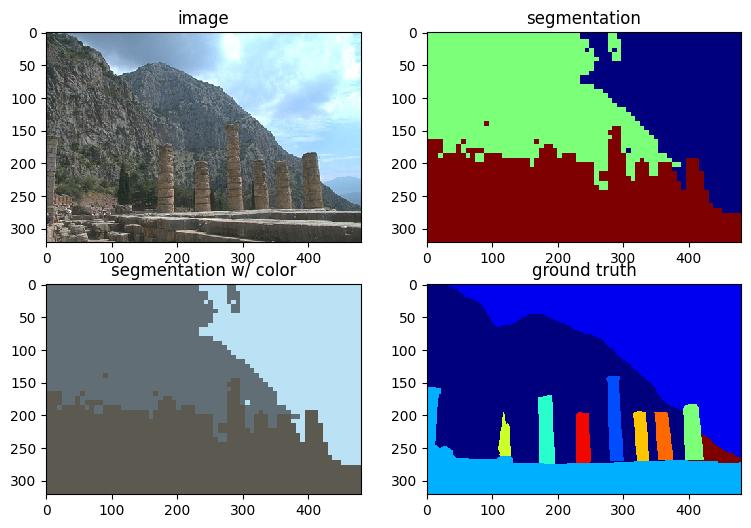

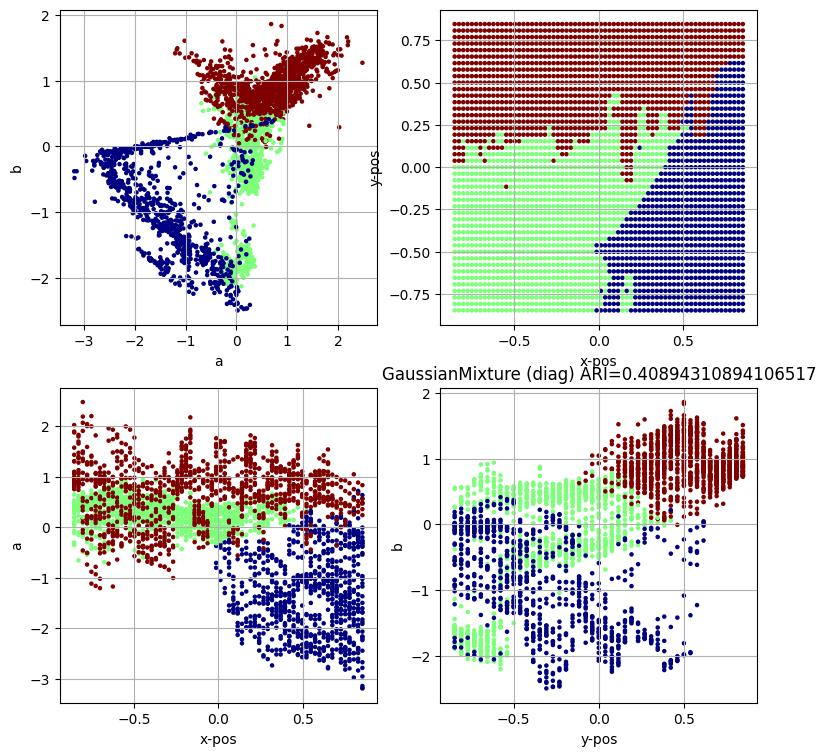

------
GaussianMixture (diag)
{'n_components': 4}


<Figure size 640x480 with 0 Axes>

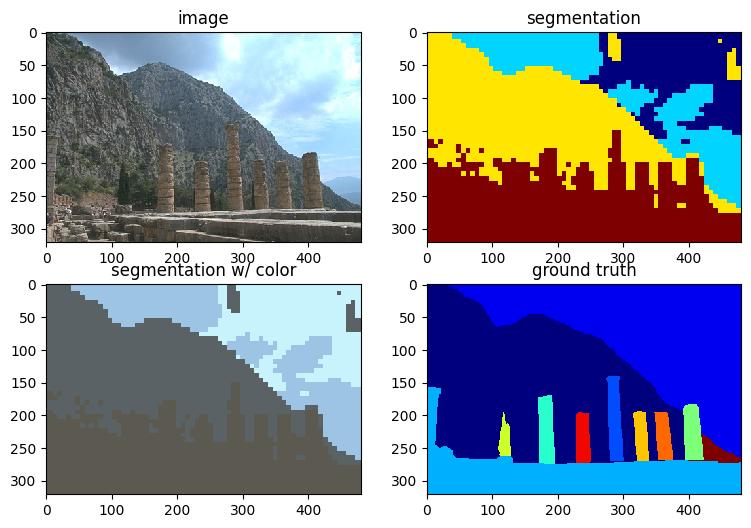

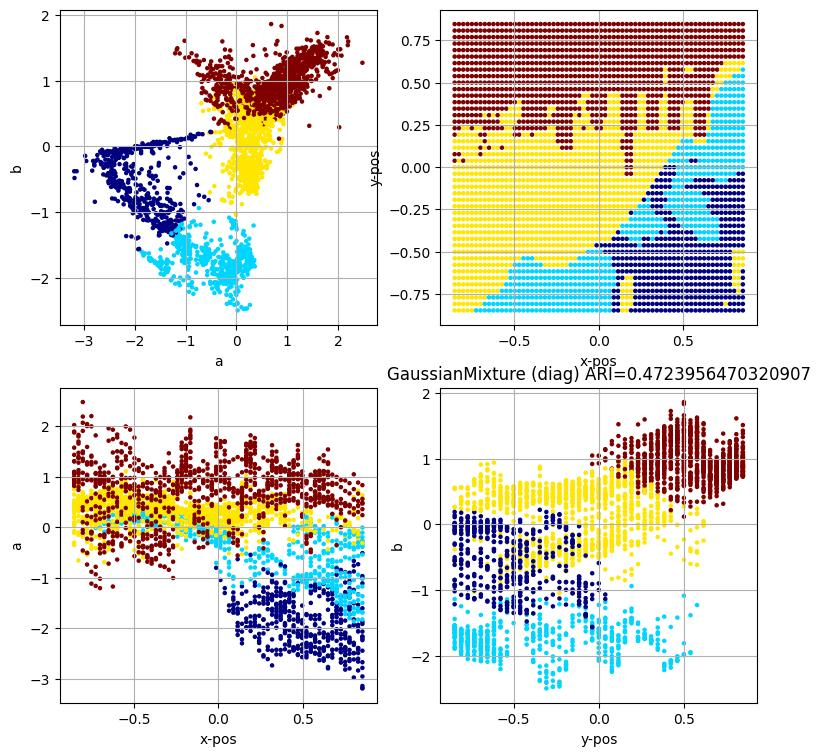

------
GaussianMixture (diag)
{'n_components': 5}


<Figure size 640x480 with 0 Axes>

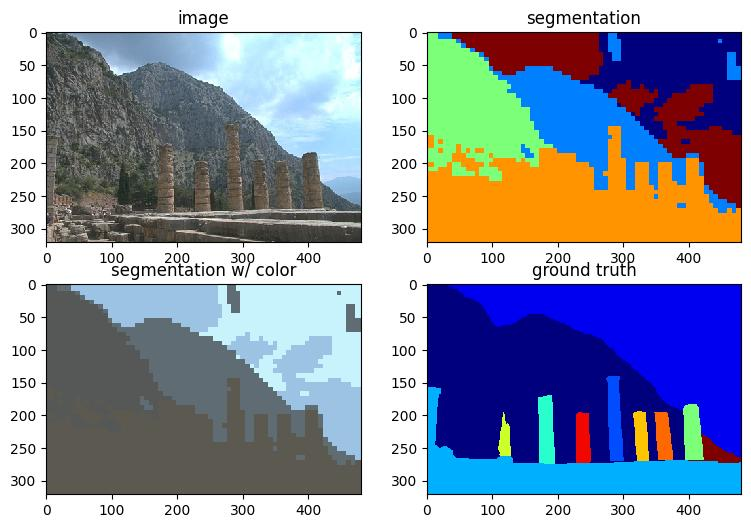

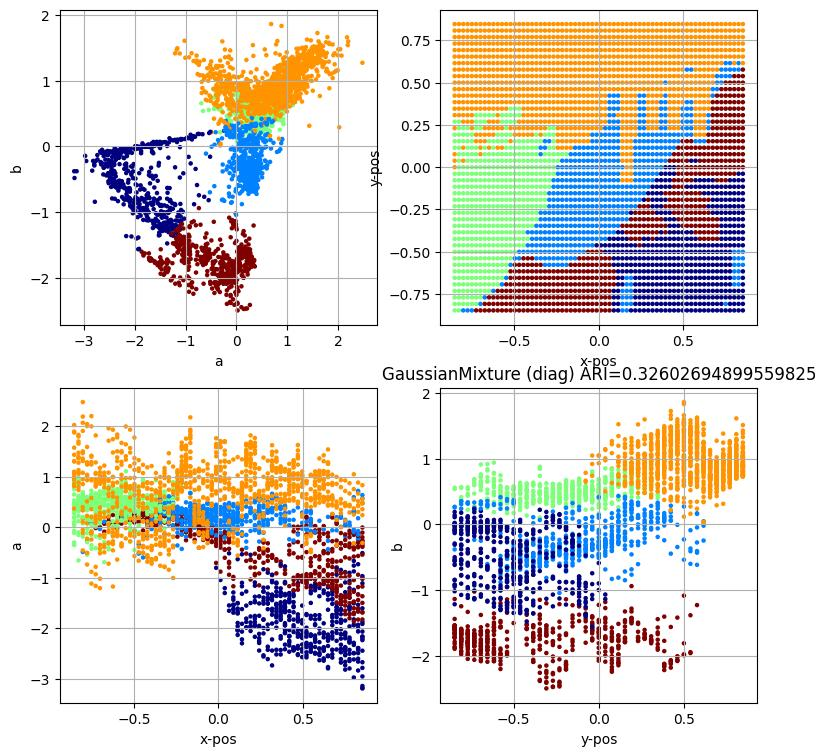

------
GaussianMixture (diag)
{'n_components': 6}


<Figure size 640x480 with 0 Axes>

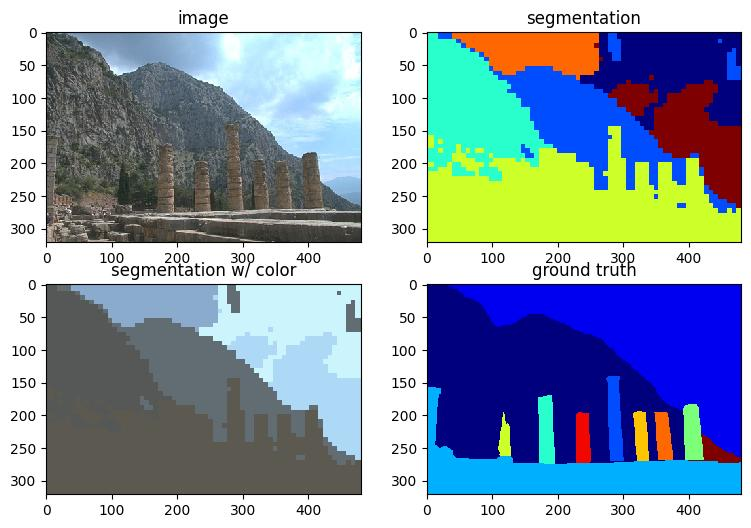

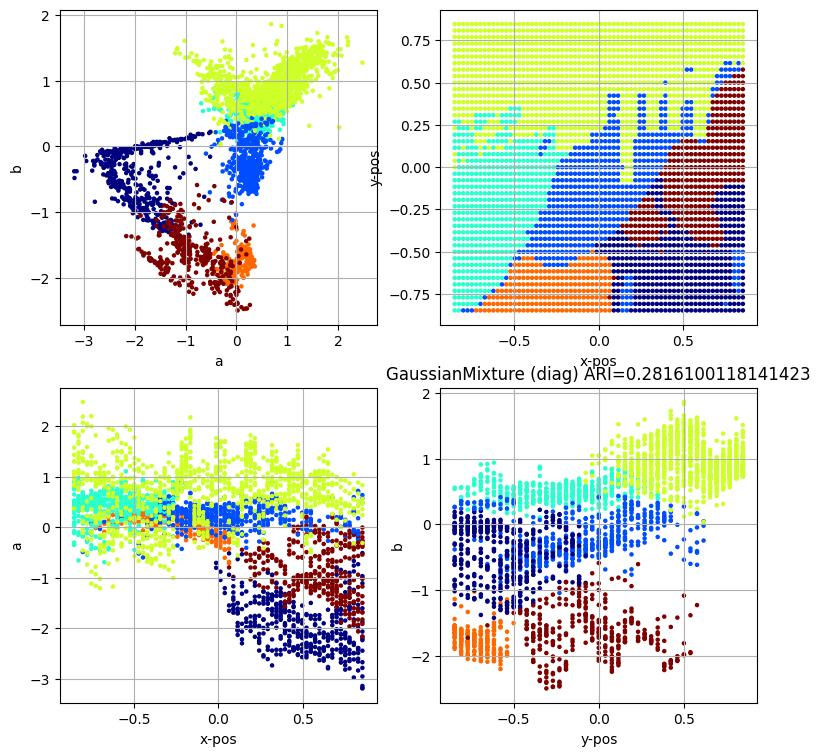

------
GaussianMixture (diag)
{'n_components': 7}


<Figure size 640x480 with 0 Axes>

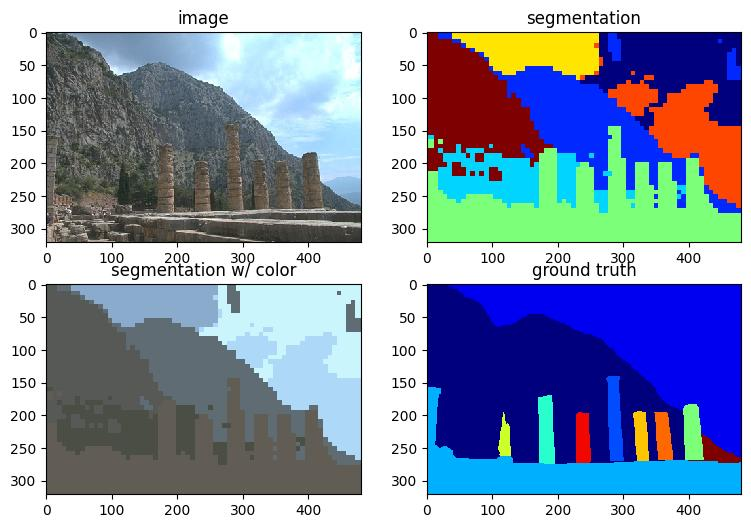

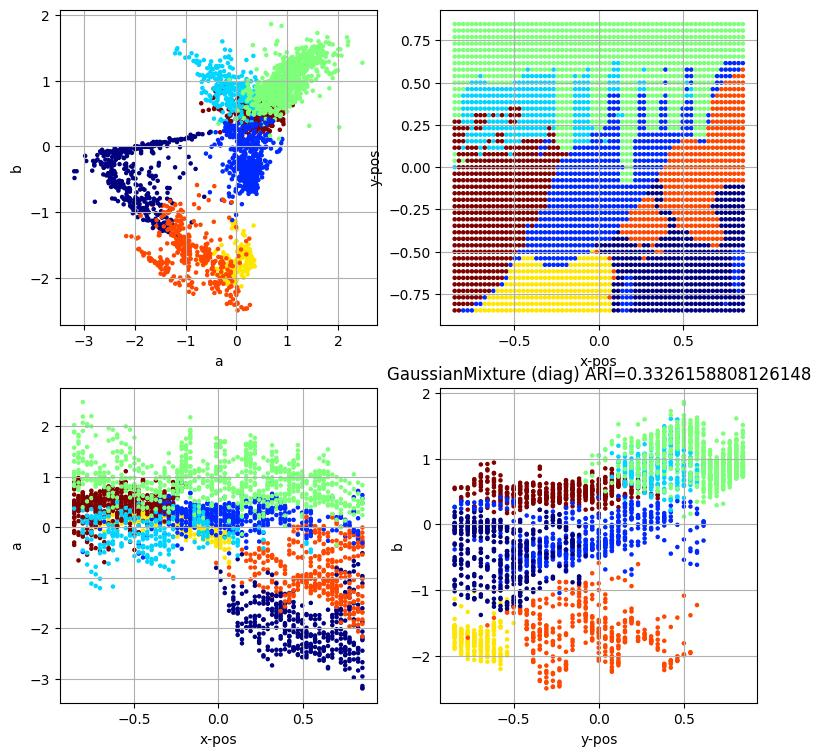

------
GaussianMixture (diag)
{'n_components': 8}


<Figure size 640x480 with 0 Axes>

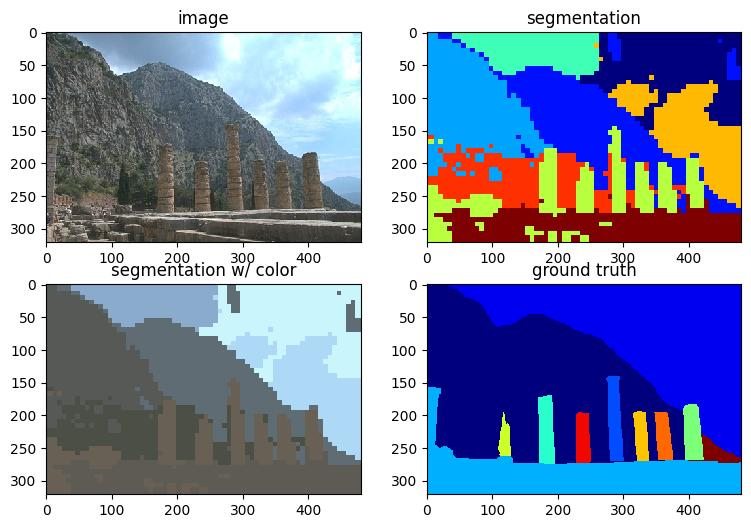

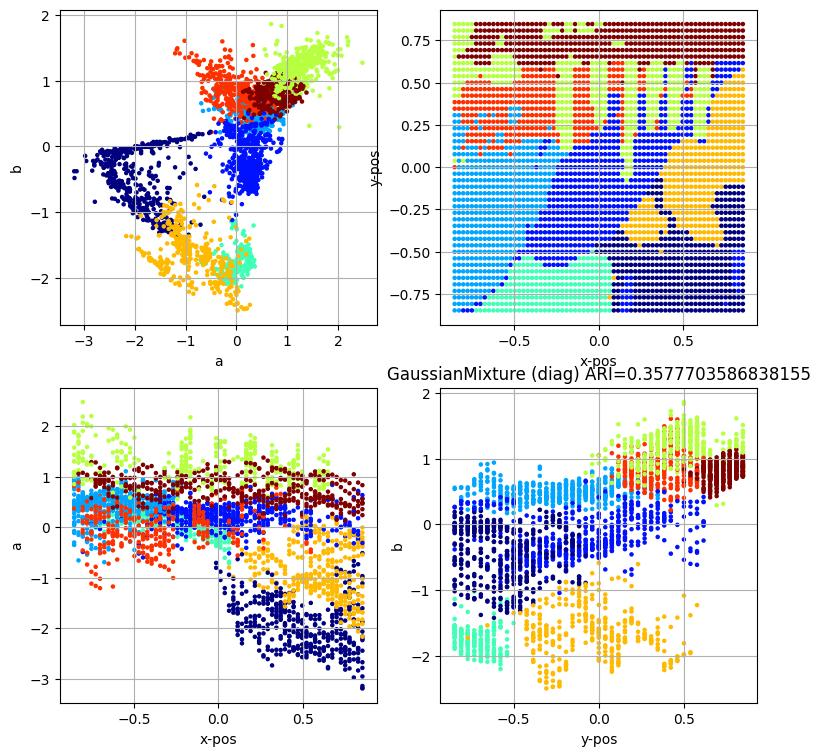

------
GaussianMixture (diag)
{'n_components': 9}


<Figure size 640x480 with 0 Axes>

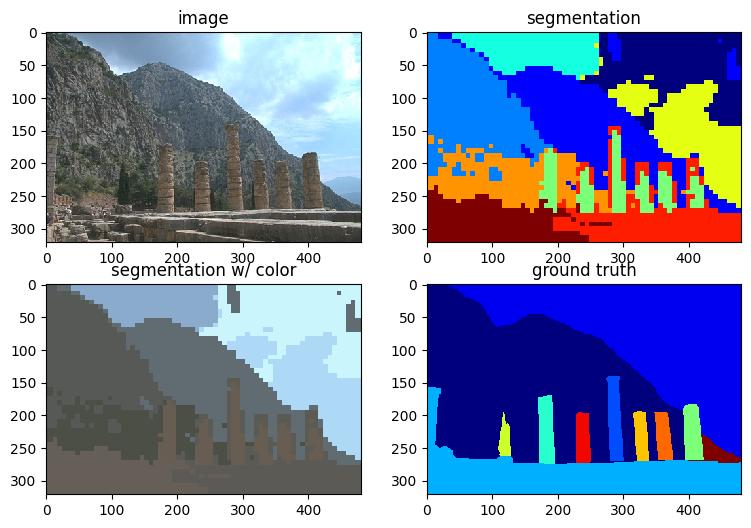

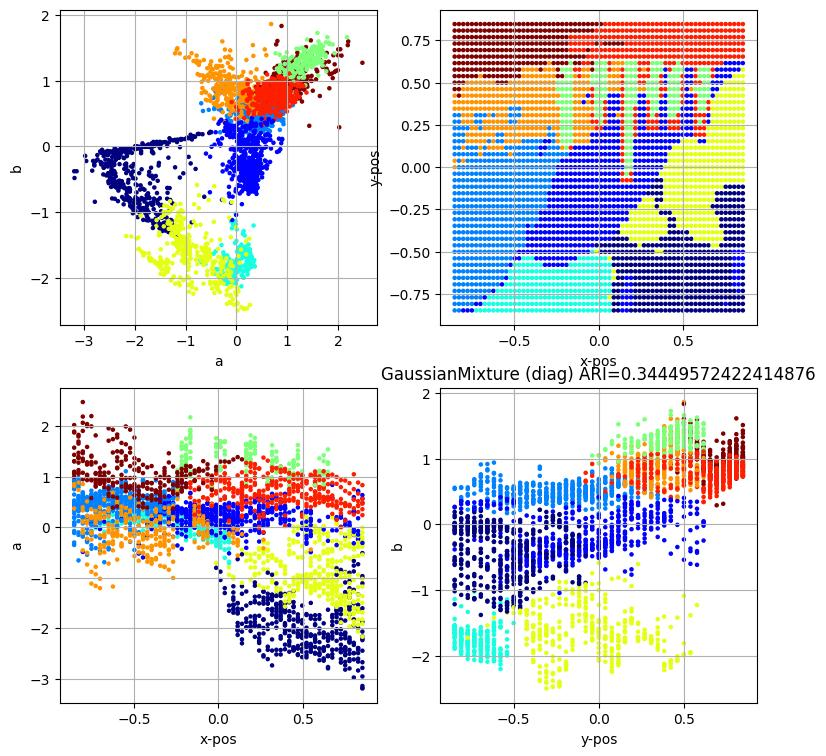

------
GaussianMixture (diag)
{'n_components': 10}


<Figure size 640x480 with 0 Axes>

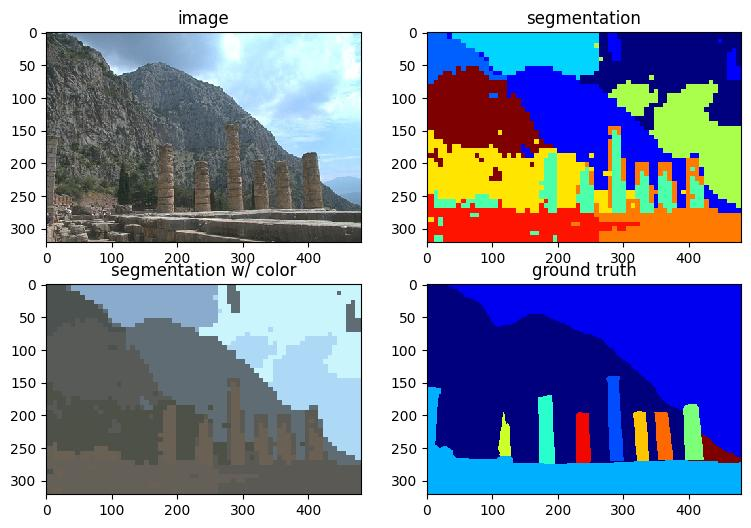

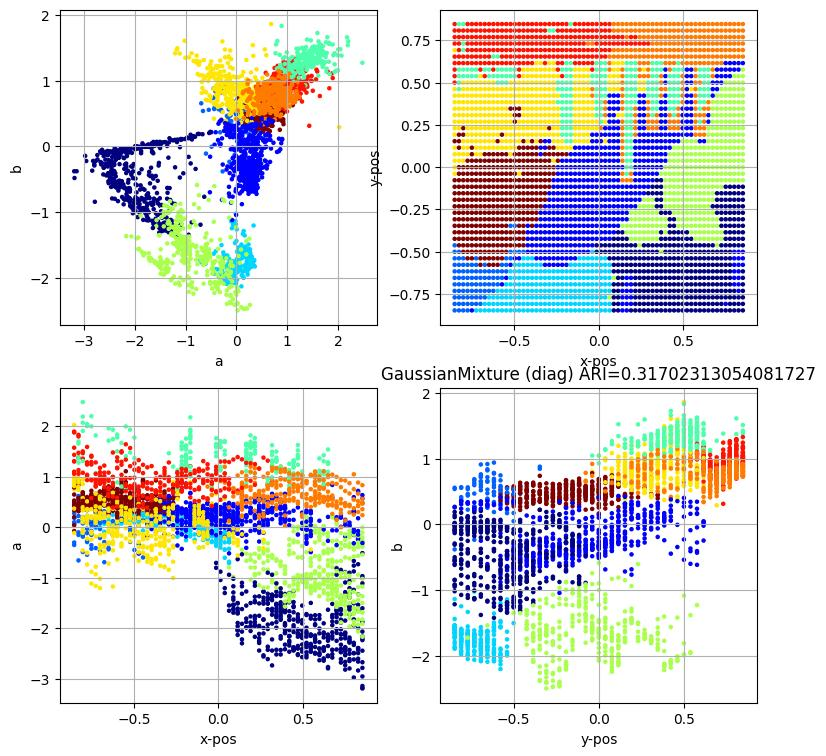

------
GaussianMixture (full)
{'n_components': 2}


<Figure size 640x480 with 0 Axes>

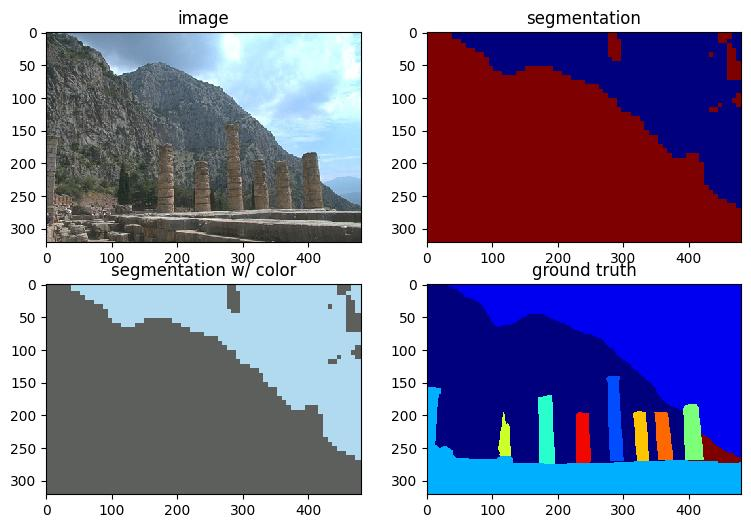

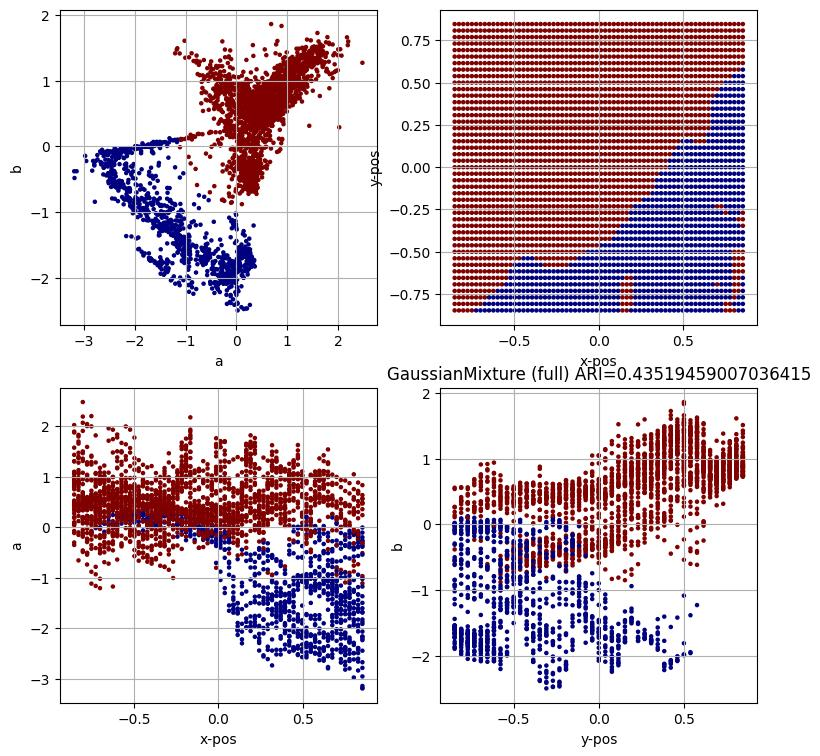

------
GaussianMixture (full)
{'n_components': 3}


<Figure size 640x480 with 0 Axes>

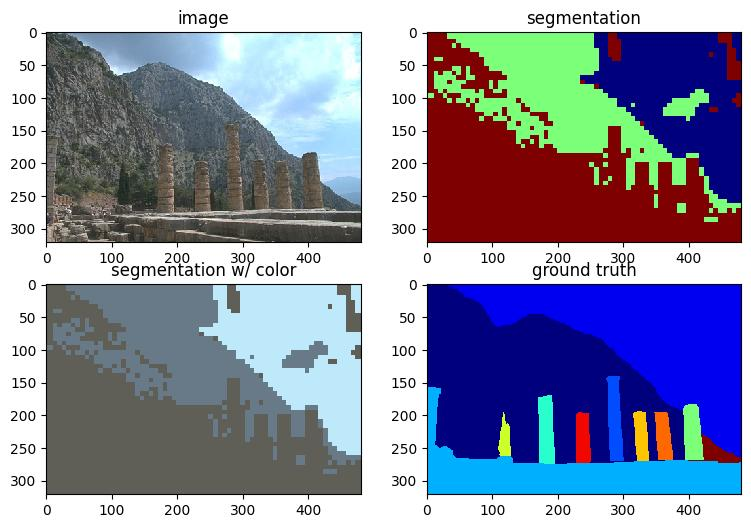

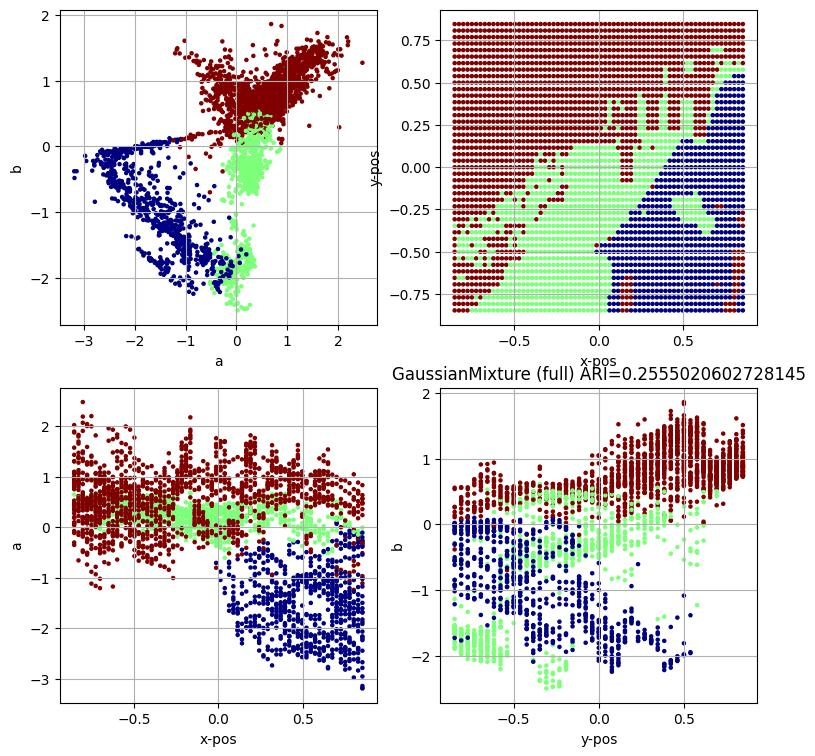

------
GaussianMixture (full)
{'n_components': 4}


<Figure size 640x480 with 0 Axes>

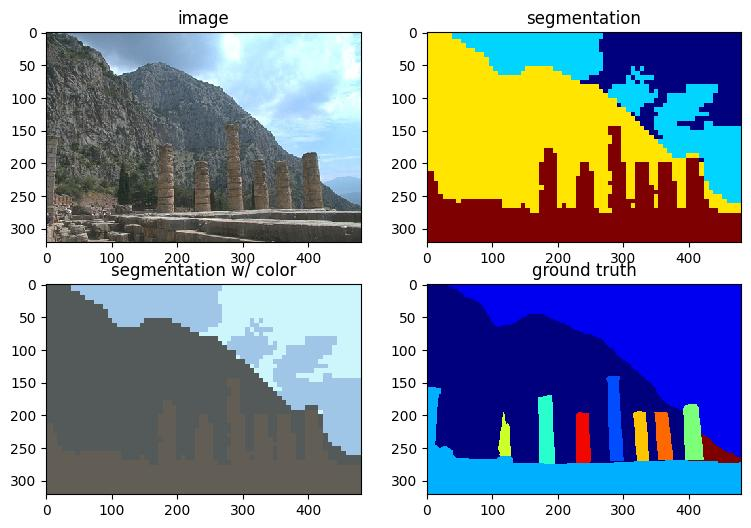

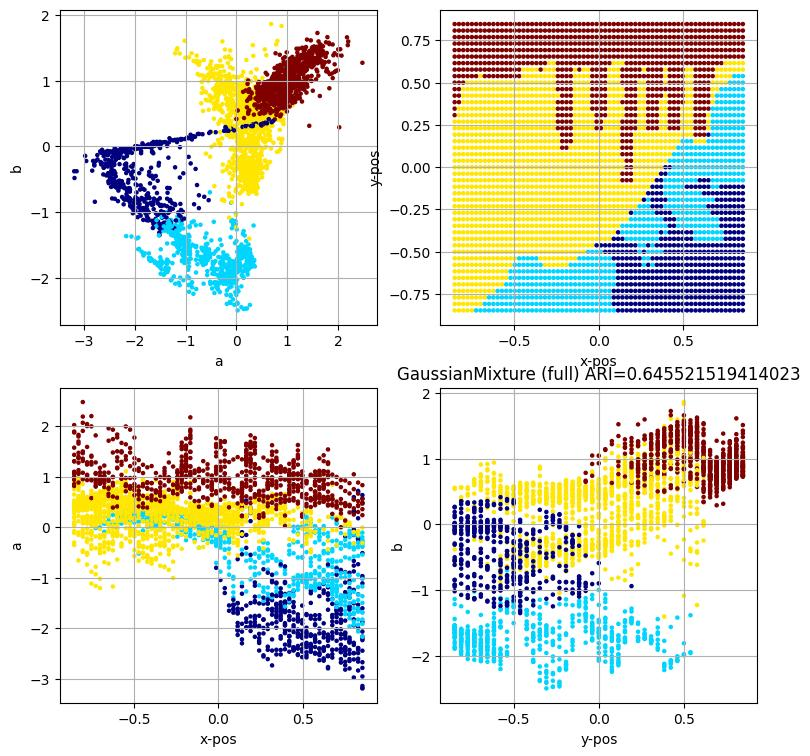

------
GaussianMixture (full)
{'n_components': 5}


<Figure size 640x480 with 0 Axes>

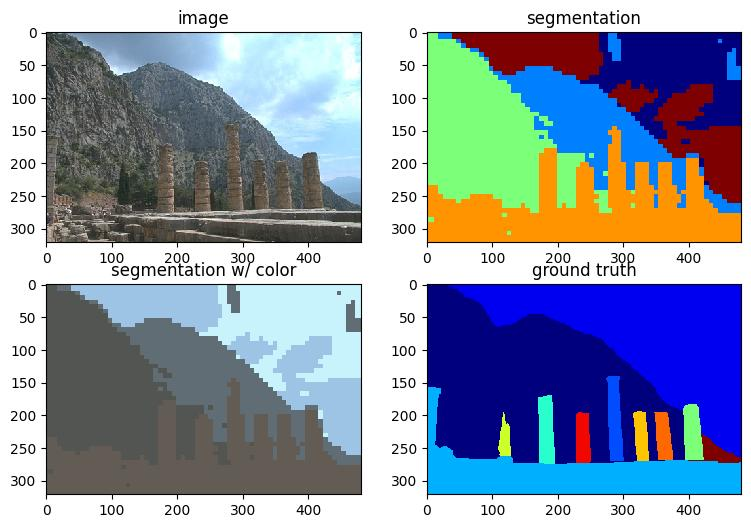

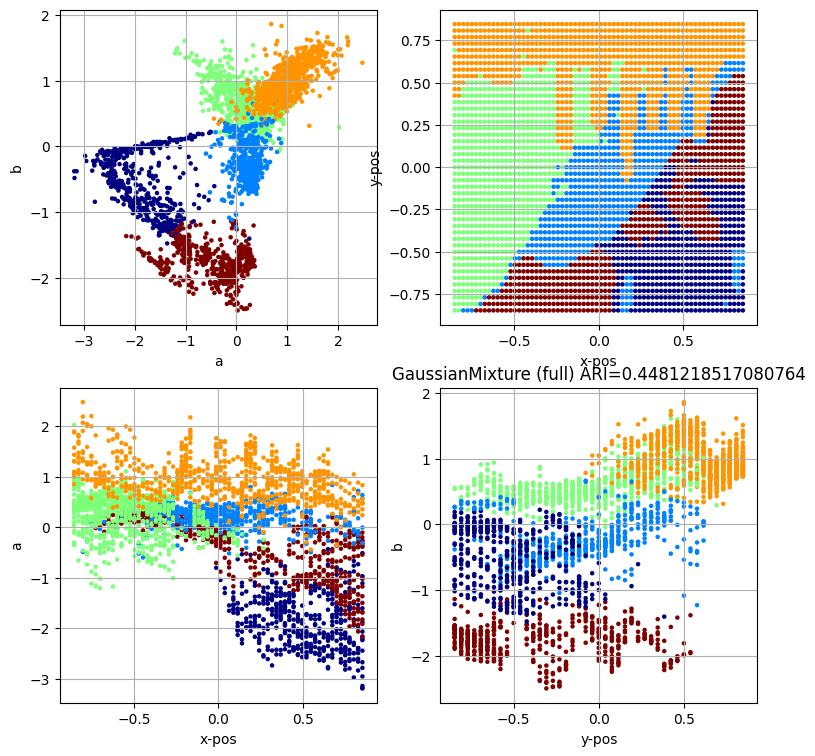

------
GaussianMixture (full)
{'n_components': 6}


<Figure size 640x480 with 0 Axes>

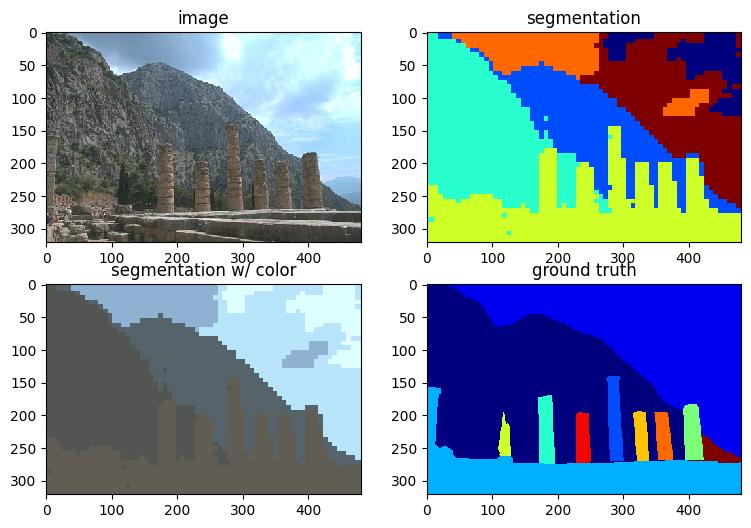

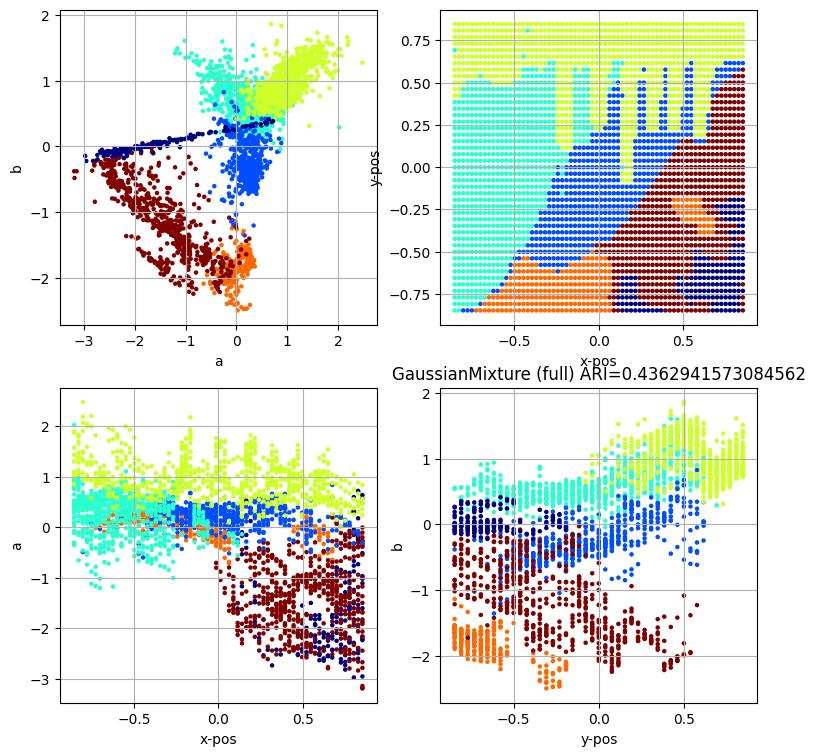

------
GaussianMixture (full)
{'n_components': 7}


<Figure size 640x480 with 0 Axes>

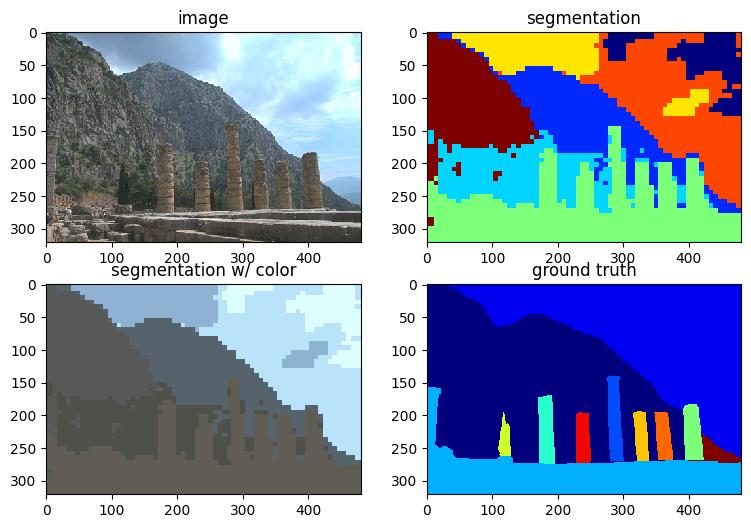

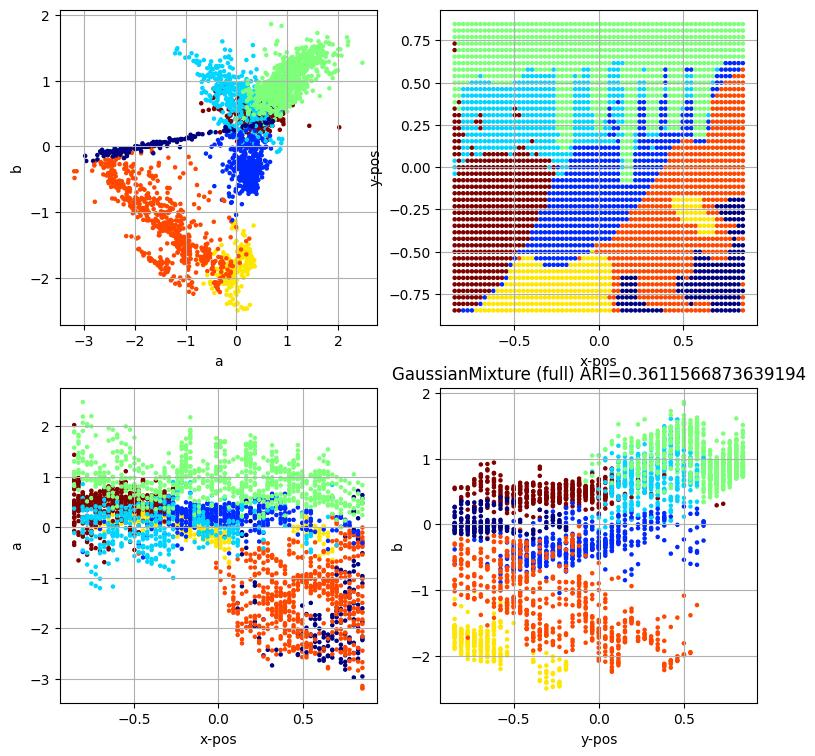

------
GaussianMixture (full)
{'n_components': 8}


<Figure size 640x480 with 0 Axes>

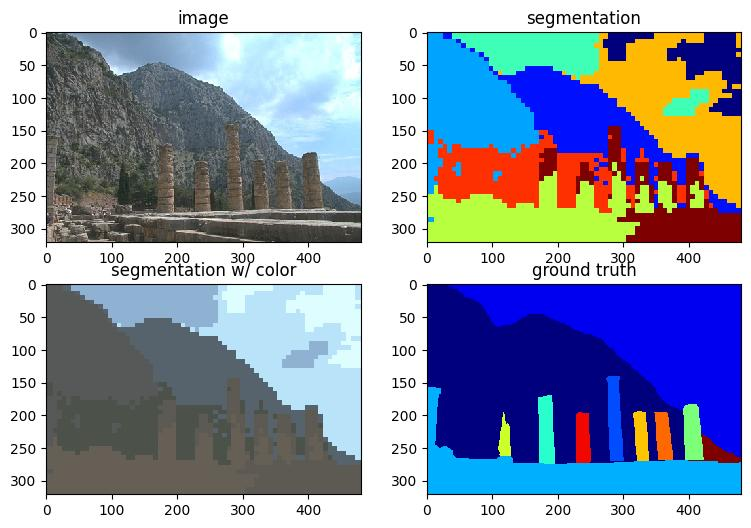

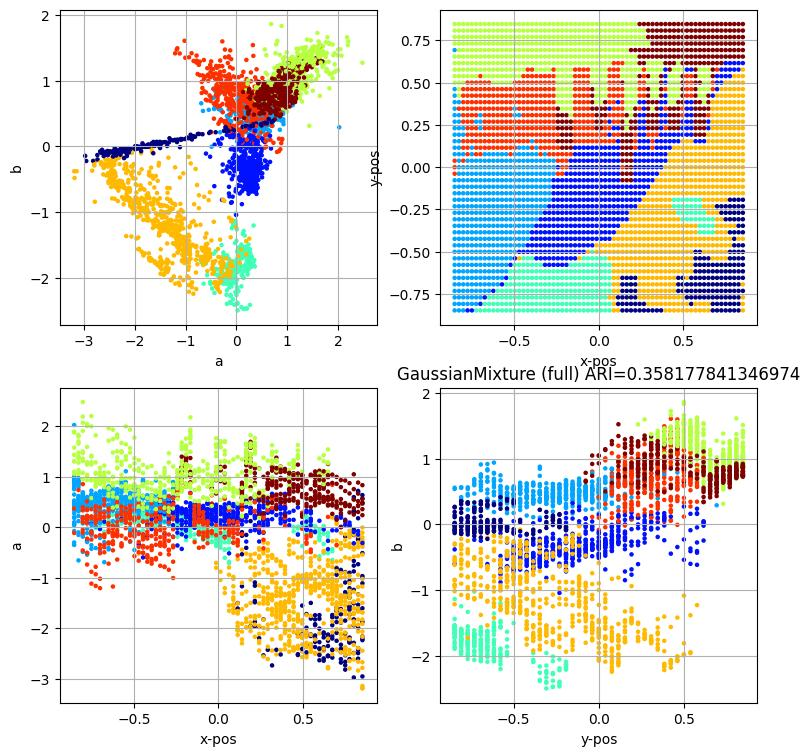

------
GaussianMixture (full)
{'n_components': 9}


<Figure size 640x480 with 0 Axes>

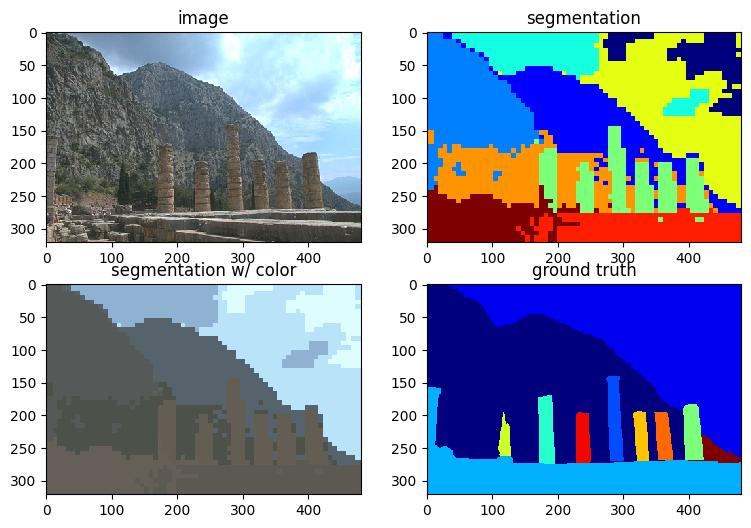

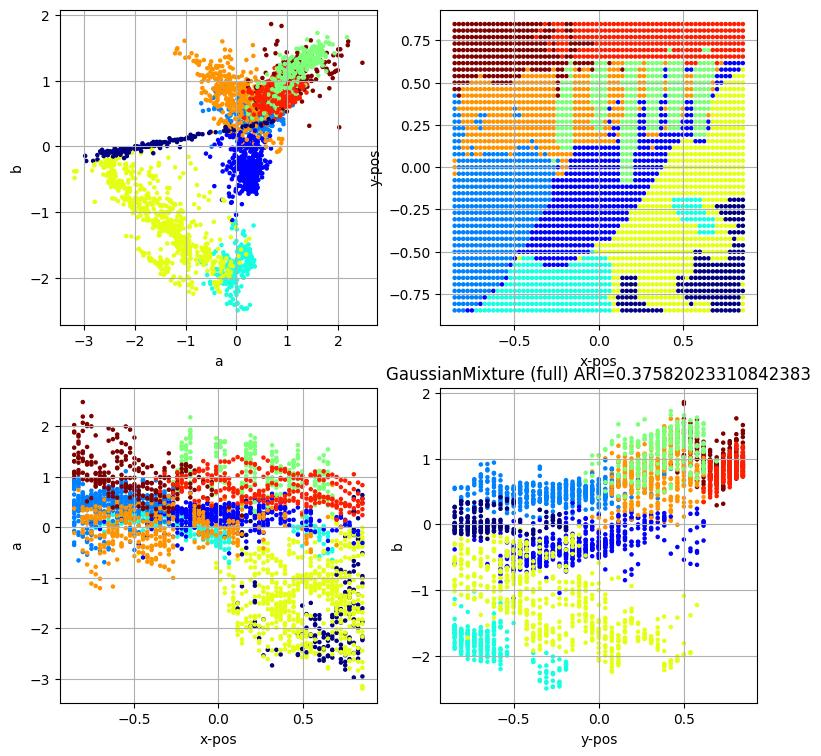

------
GaussianMixture (full)
{'n_components': 10}


<Figure size 640x480 with 0 Axes>

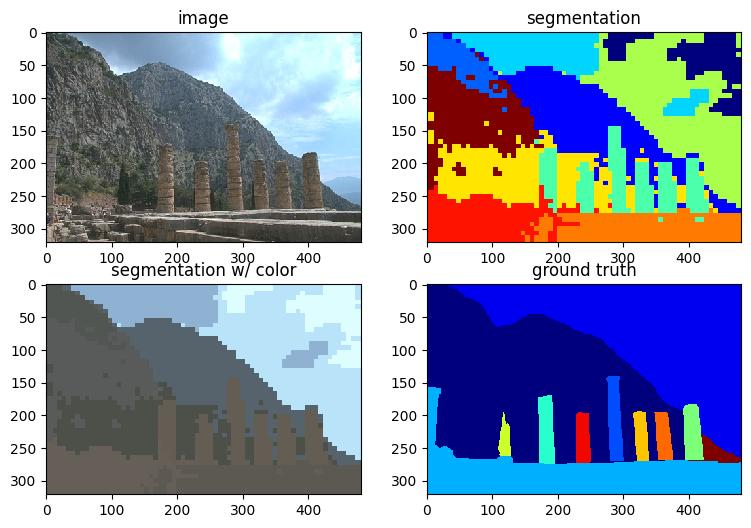

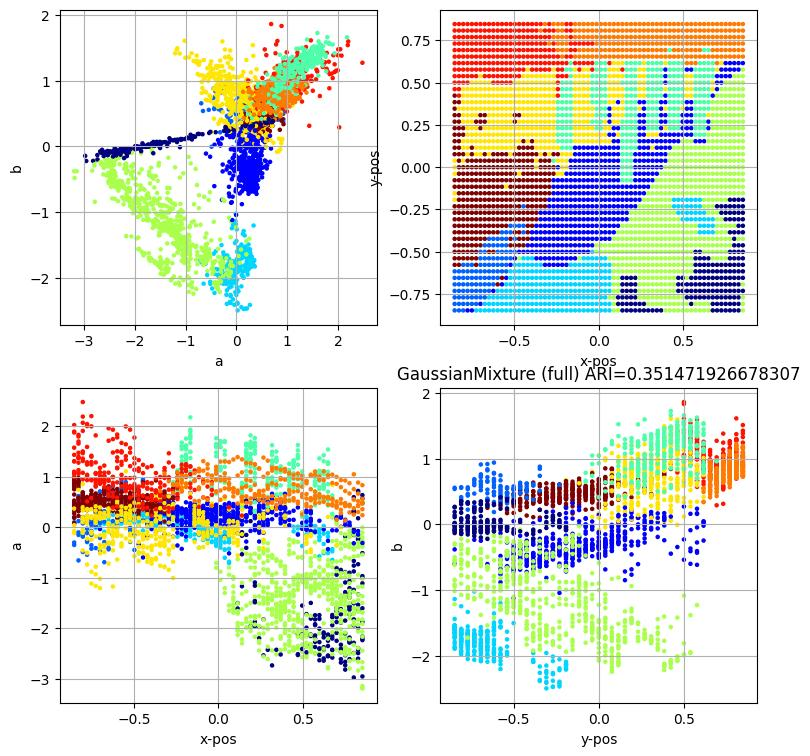

------
AgglomerativeClustering
{'n_clusters': 2}


<Figure size 640x480 with 0 Axes>

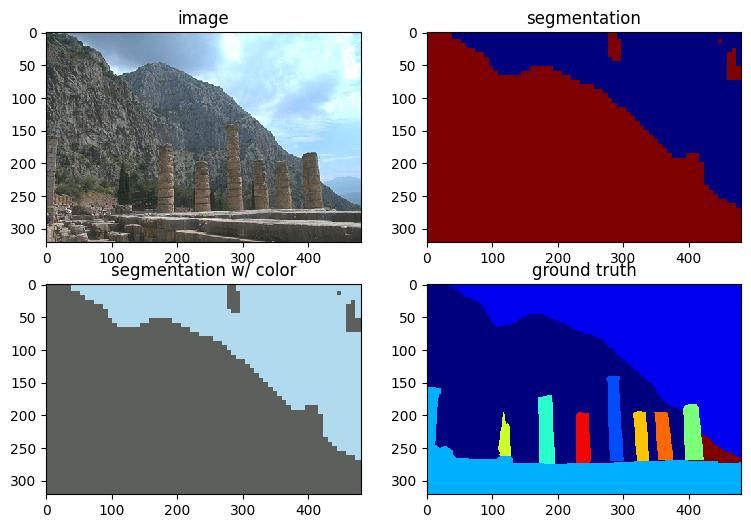

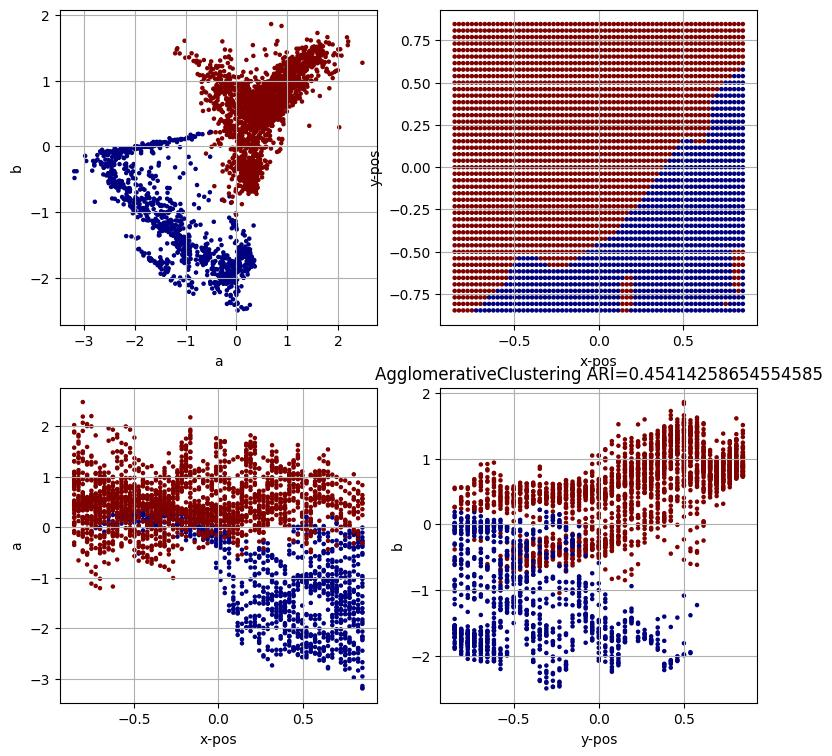

------
AgglomerativeClustering
{'n_clusters': 3}


<Figure size 640x480 with 0 Axes>

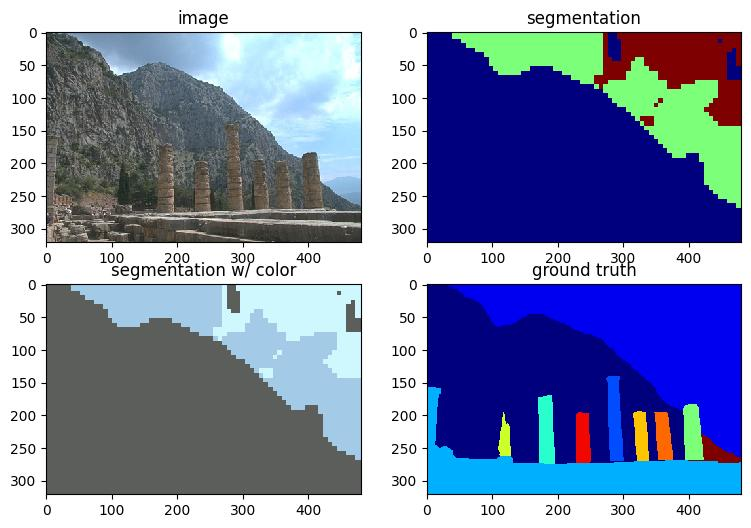

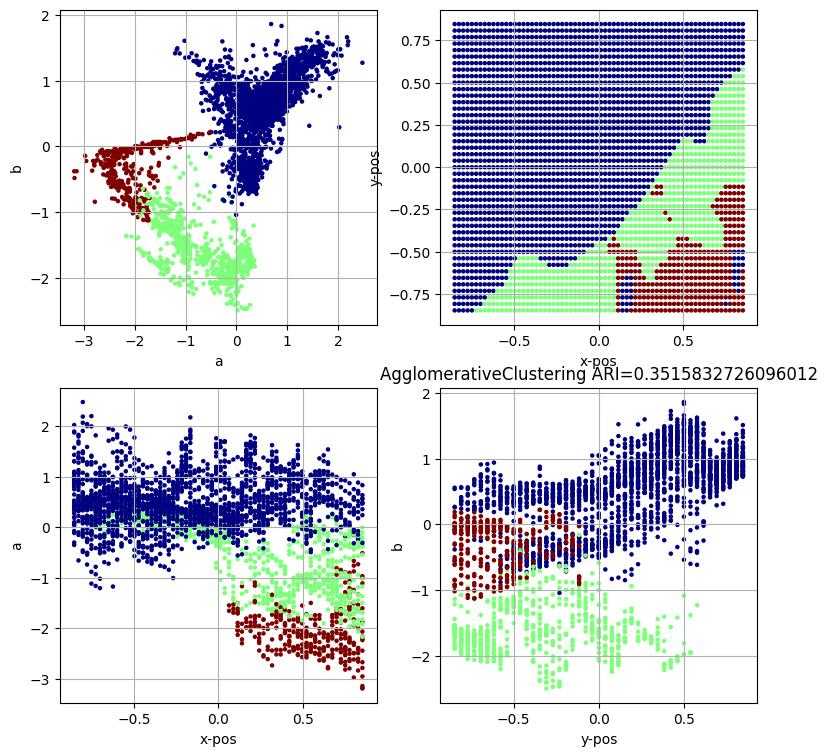

------
AgglomerativeClustering
{'n_clusters': 4}


<Figure size 640x480 with 0 Axes>

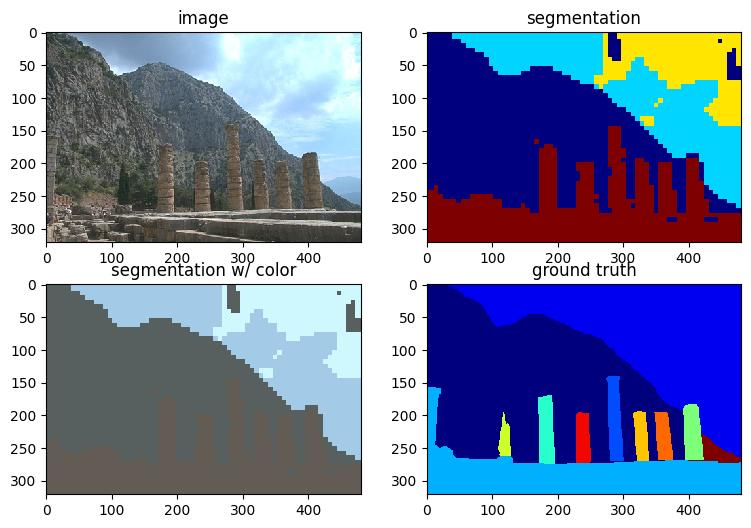

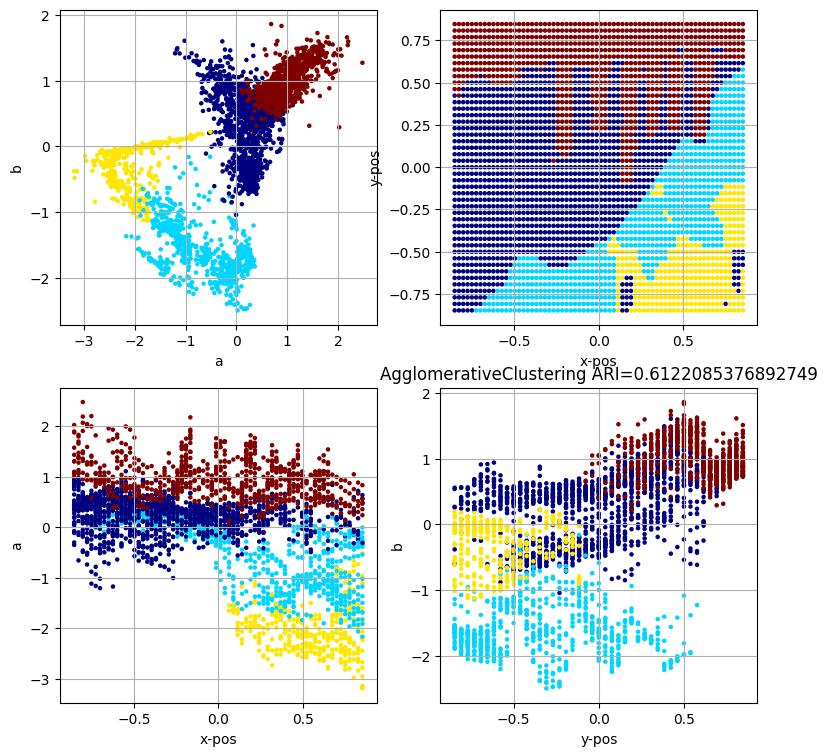

------
AgglomerativeClustering
{'n_clusters': 5}


<Figure size 640x480 with 0 Axes>

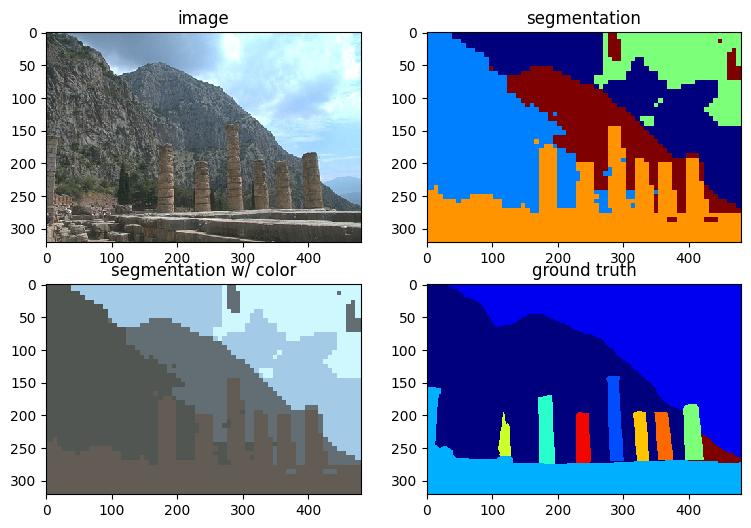

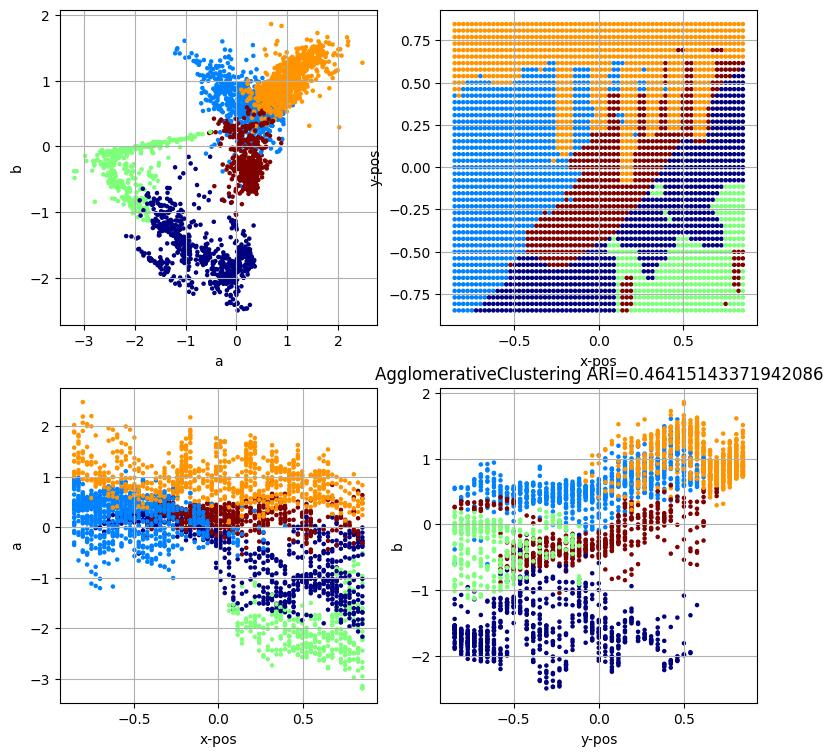

------
AgglomerativeClustering
{'n_clusters': 6}


<Figure size 640x480 with 0 Axes>

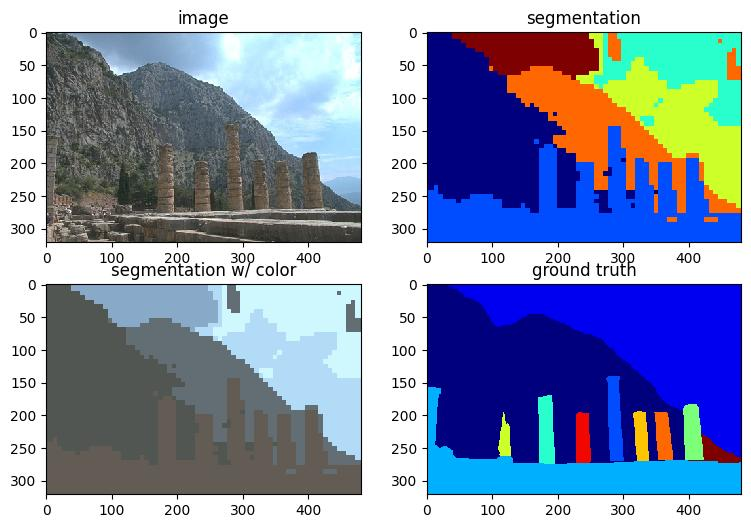

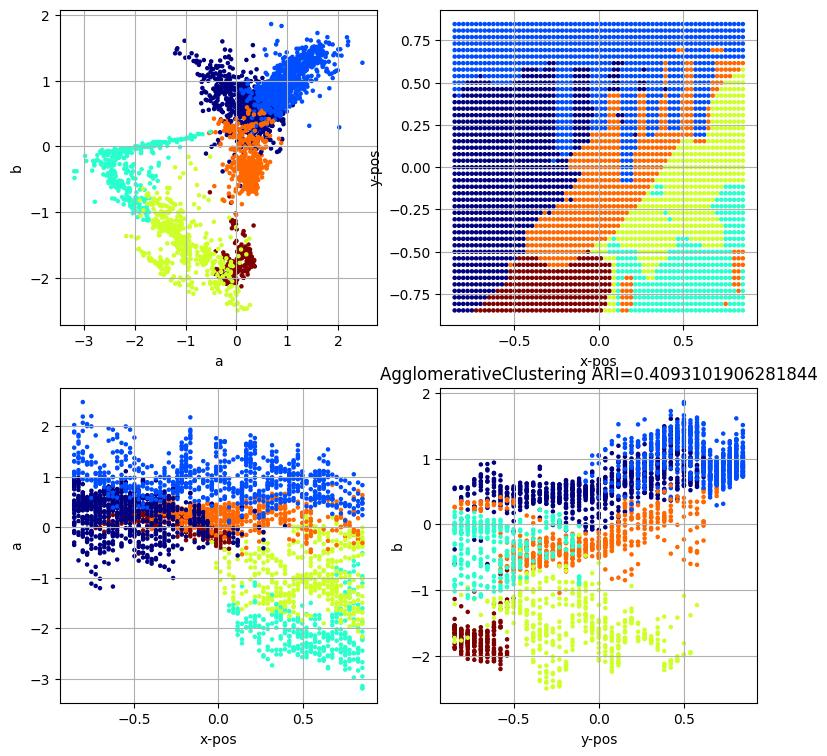

------
AgglomerativeClustering
{'n_clusters': 7}


<Figure size 640x480 with 0 Axes>

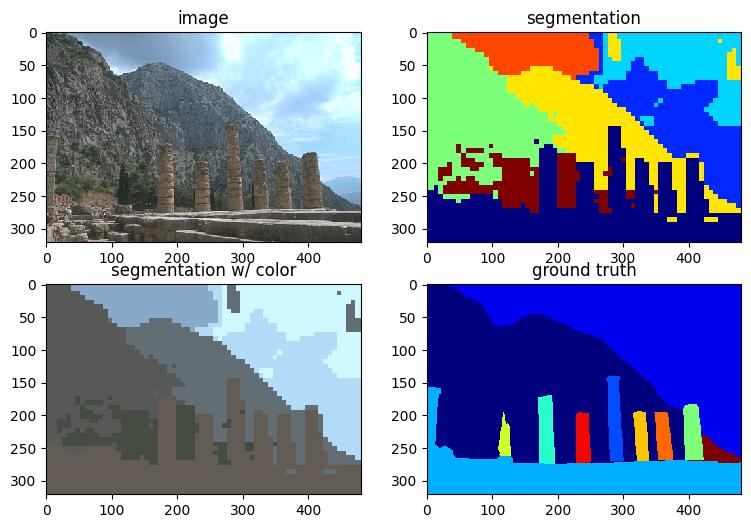

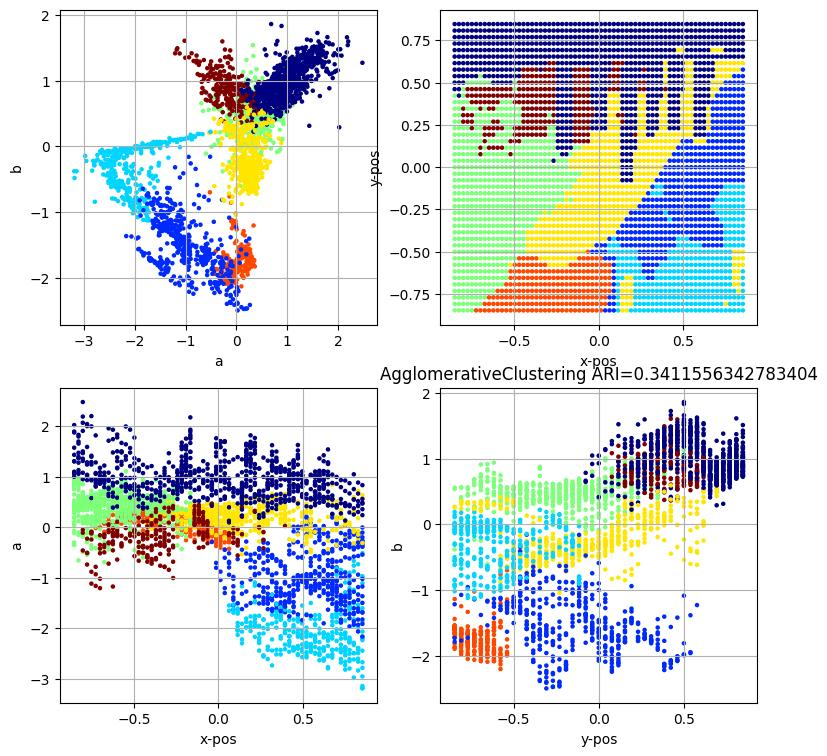

------
AgglomerativeClustering
{'n_clusters': 8}


<Figure size 640x480 with 0 Axes>

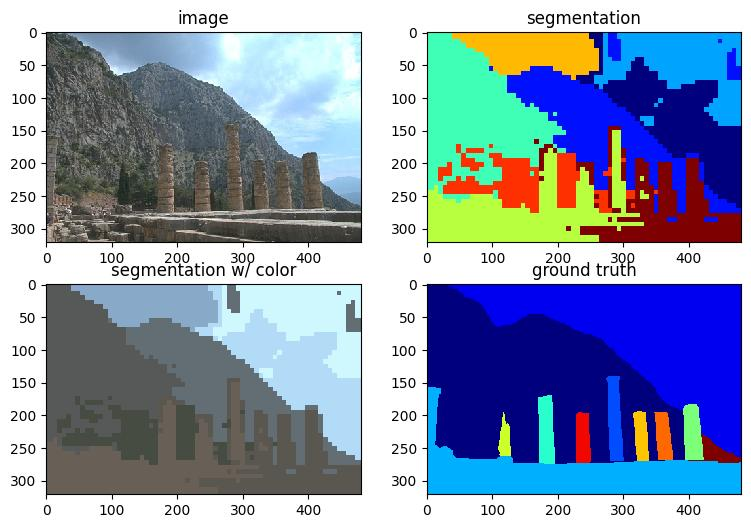

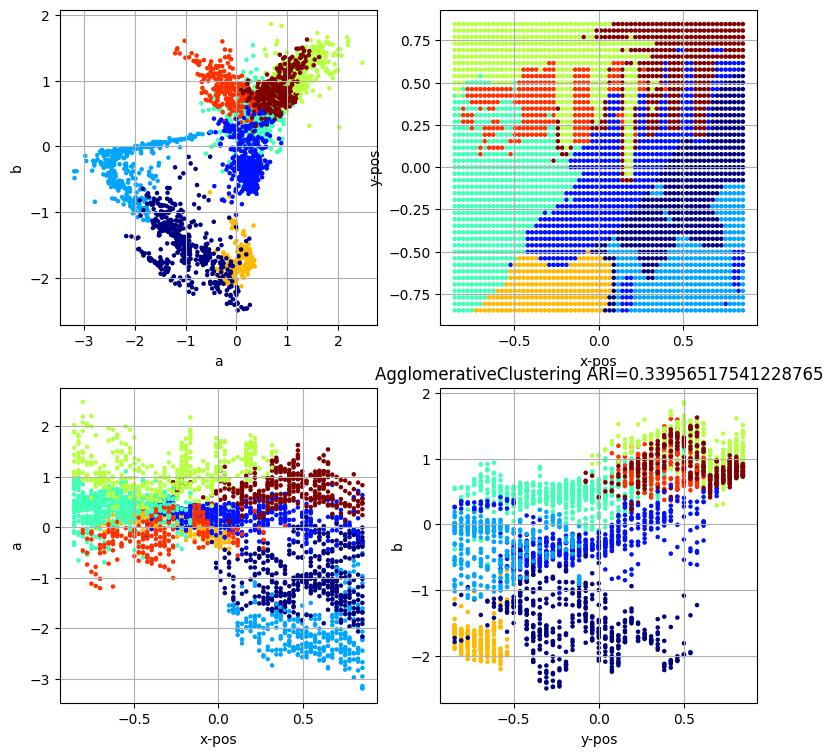

------
AgglomerativeClustering
{'n_clusters': 9}


<Figure size 640x480 with 0 Axes>

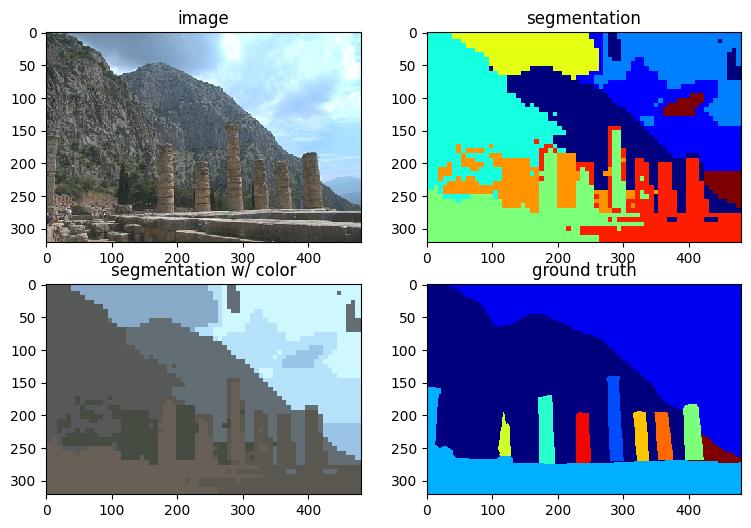

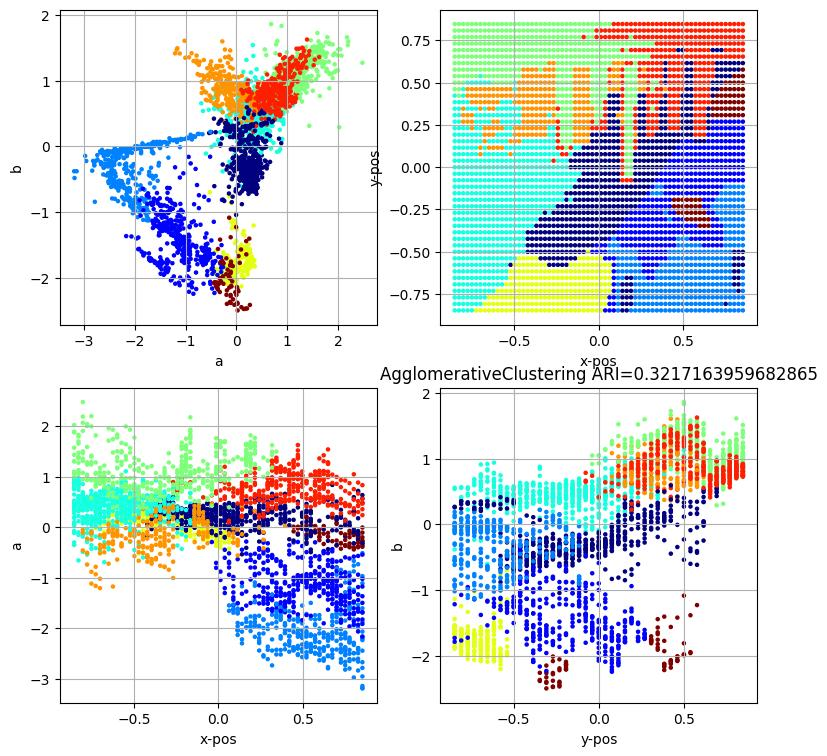

------
AgglomerativeClustering
{'n_clusters': 10}


<Figure size 640x480 with 0 Axes>

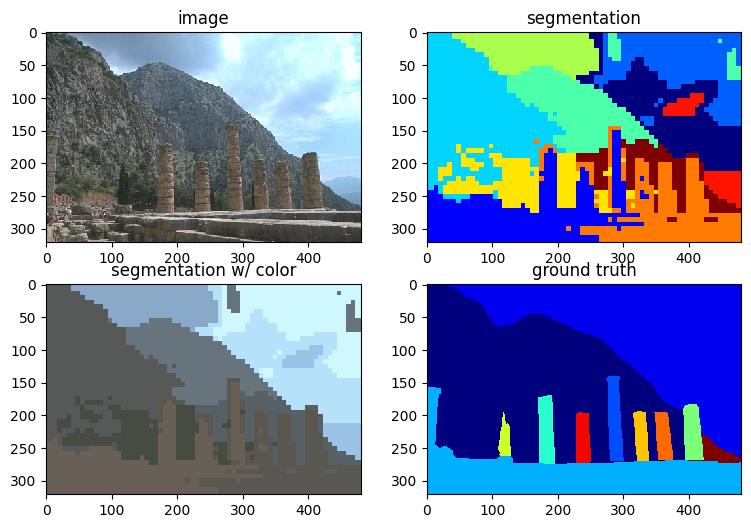

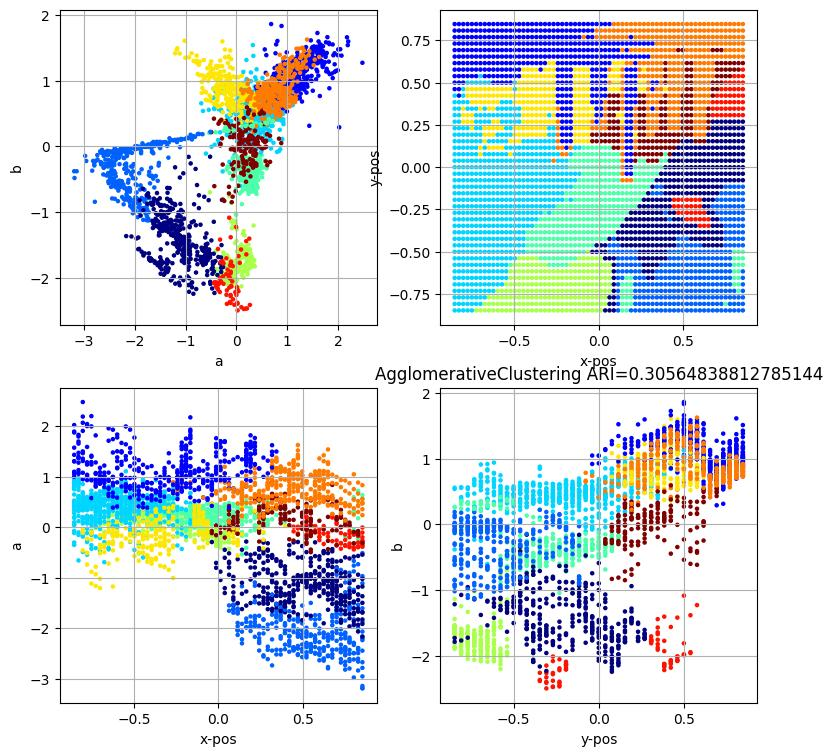

------
DBSCAN
{'eps': 0.2}


<Figure size 640x480 with 0 Axes>

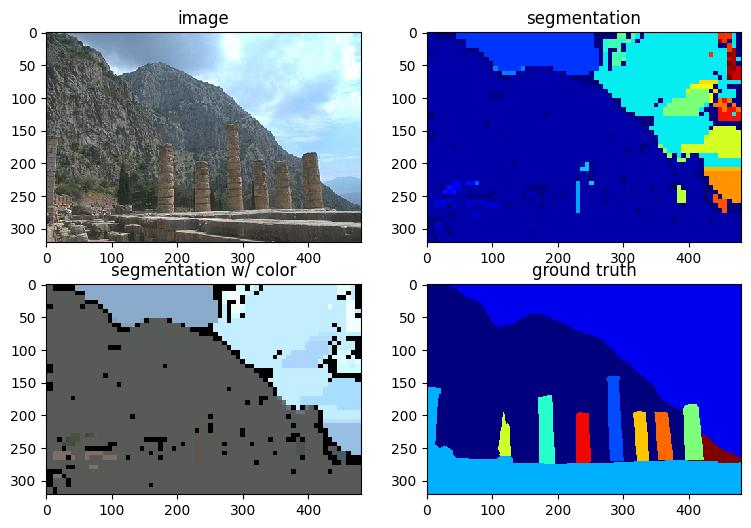

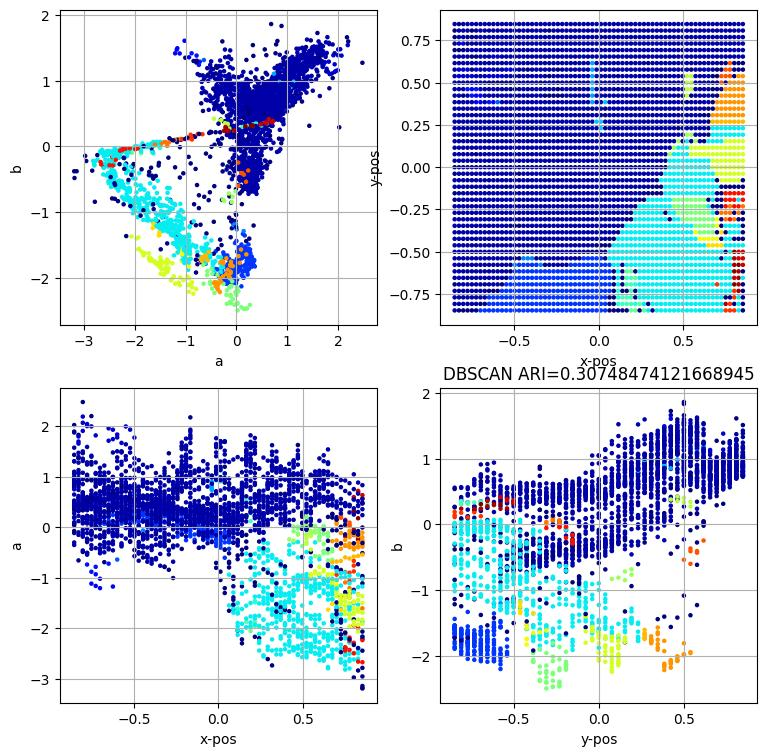

------
DBSCAN
{'eps': 0.3}


<Figure size 640x480 with 0 Axes>

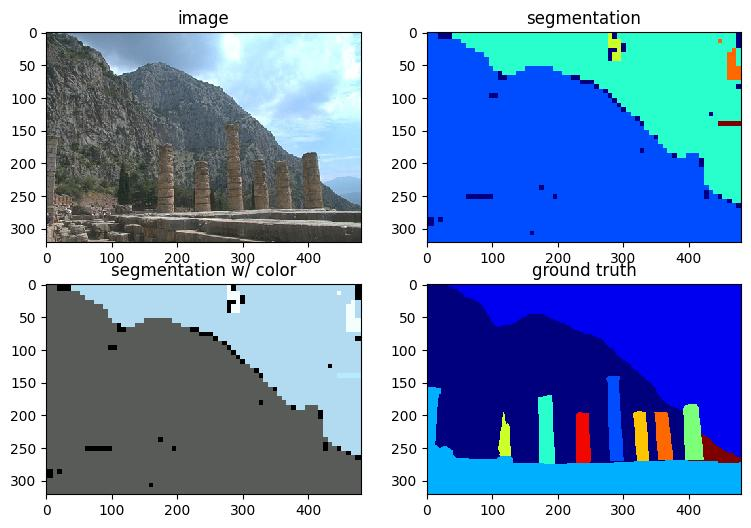

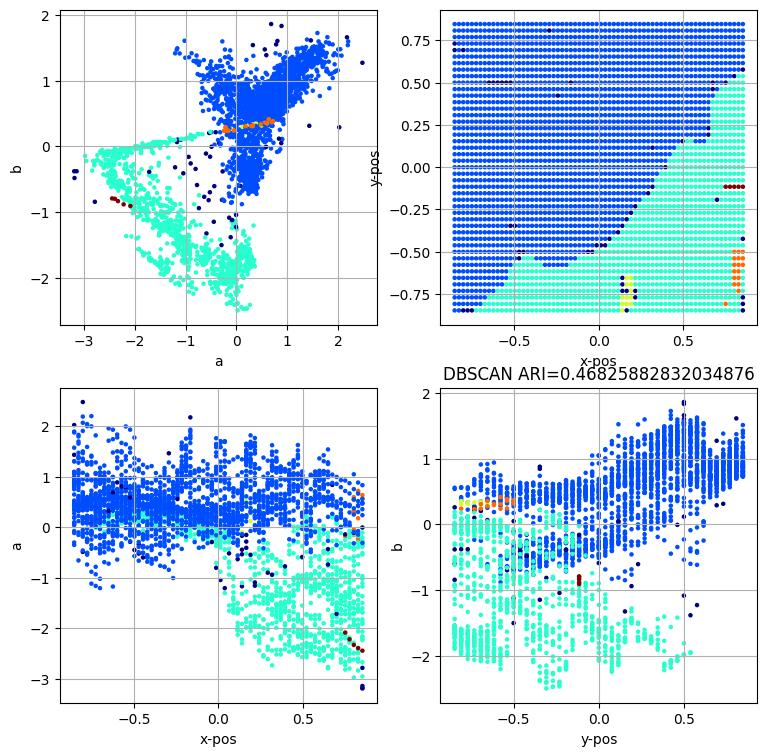

------
DBSCAN
{'eps': 0.5}


<Figure size 640x480 with 0 Axes>

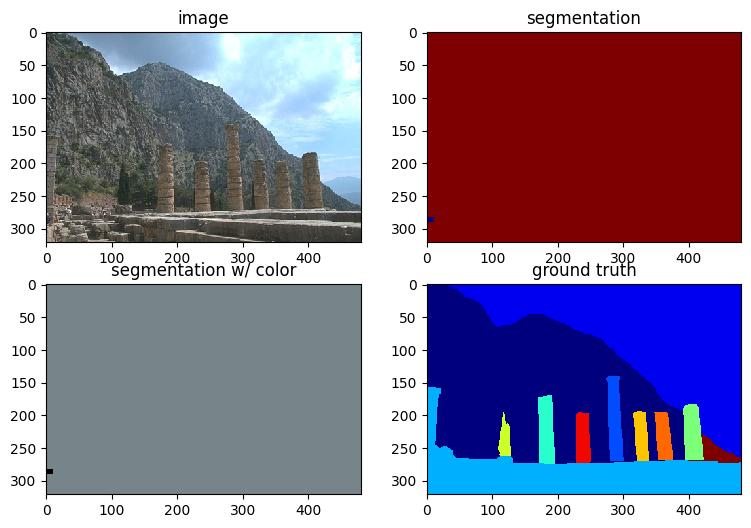

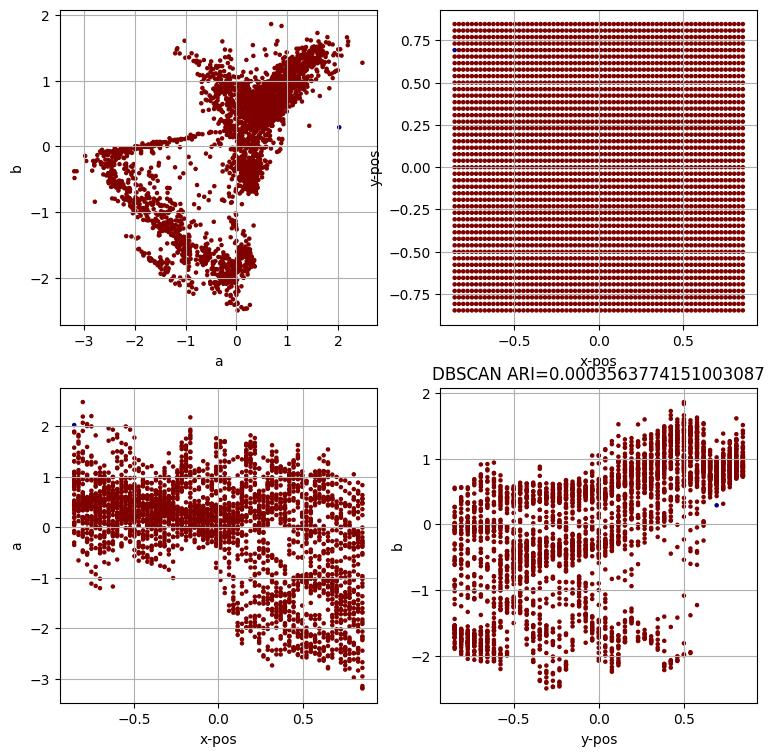

------
DBSCAN
{'eps': 1.0}


<Figure size 640x480 with 0 Axes>

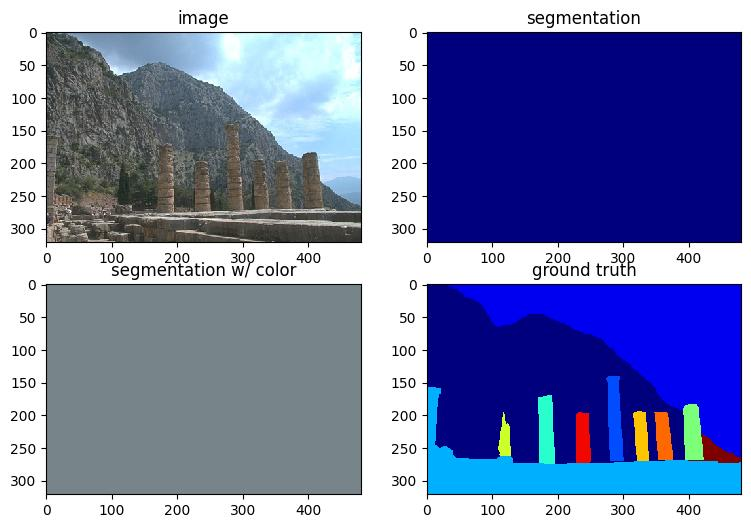

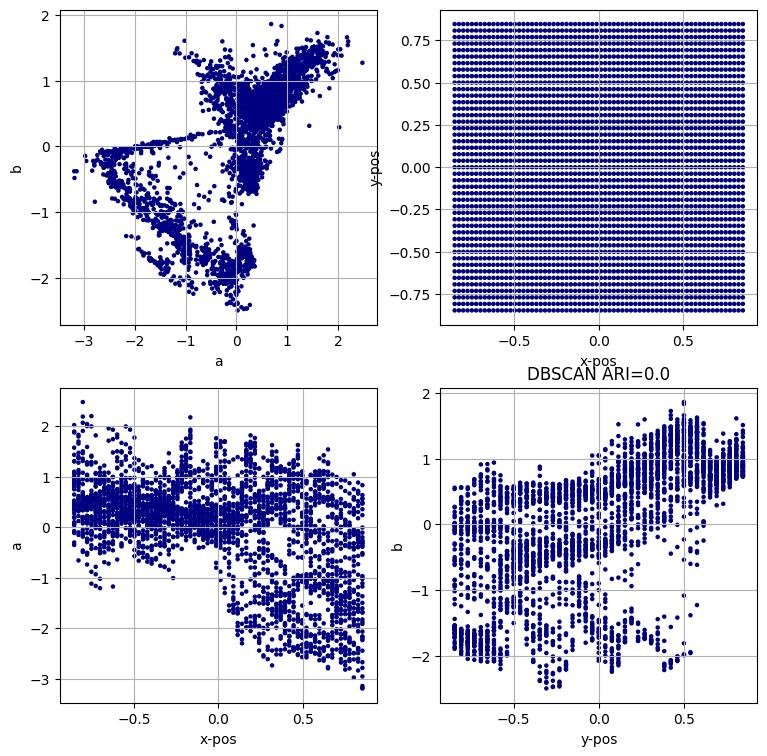

In [18]:
for L in results2:
    print('------')
    print(L['name'])
    print(L['param'])
    plt.figure()
    # show the segmentation
    showsegm(L['segm'], img)

    # show the scatter plot
    showscatter(X,L['Y'])
    plt.title(L['name'] + " ARI=" + str(L['ari']))
    plt.show()

_Which method performs the best?  Why?_
- **GaussianMixture with `covariance_type='full'`, `n_components=4` performs the best, ARI = 0.646.** I think the reason is the shape of the clusters in the 4-D feature space: a single object stretches over a range of (x,y) positions while its color only varies a little, so each cluster is long and thin rather than round (you can see this in the x-pos vs. a / y-pos vs. b scatter plots). A full-covariance GMM can model such elongated clusters with different sizes and orientations, while K-means implicitly assumes spherical clusters with similar size, so it has to cut the long clusters into pieces — that's why KMeans K=4 is a bit lower (0.602), and ward AgglomerativeClustering is similar (0.612). The diag GMM is clearly worse (0.472) because with a diagonal covariance it cannot capture the correlation between the position and color dimensions. All of these methods peak at K=4. DBSCAN works badly here: with eps=0.2 it fragments into 28 clusters (ARI 0.307), and once eps is a bit larger everything merges into a single cluster (ARI ≈ 0). The features are sampled on a regular grid over the image, so the density is quite uniform everywhere and there is no "dense clusters vs. sparse noise" structure for a density-based method to find.

_Does including the position features improve the segmentation results?_
- **Yes.** With color features only, the best ARI was 0.540 (KMeans, K=4); after adding the position features it goes up to 0.646. The segmentation also looks much smoother: with color only there are many isolated "loner" pixels, because two far-away pixels with the same color get assigned to the same cluster even though they are in different parts of the image; once (x,y) is part of the feature vector, a cluster has to be similar in color *and* close in location, so the loner pixels basically disappear. However the improvement is limited: the ground truth has 11 segments, but the ARI still peaks at K=4 in both cases. Looking at the image, the 6 small brown objects have almost the same average color (RGB around (95, 90, 78)), so color alone can never separate them, and adding position only helps a little — each of them is quite small (only a few dozen samples in the 7-pixel grid), so splitting them correctly doesn't move the ARI much; the big regions (sky, gray background) dominate the score.